# Marvel CPG: Exploratory Data Analysis

**CDA 650 Experiential Learning · Client project with Globant · Team 1**
**Dataset:** Marvel CPG synthetic commercial data (Jan 2025 – Jun 2026)

---

### Table of contents
1. Introduction
2. Setup and data loading
3. Data understanding and quality checks
4. Univariate analysis
5. Bivariate and multivariate analysis
6. Time series analysis
7. The brief's KPIs (baseline values)
8. Deep dives
9. Baseline OOS model (feasibility check)
10. Key insights and what they mean for our build
11. Questions for Dr. Masse
12. Next steps

> **To run on Colab:** `Runtime → Run all`. When the file picker opens in section 2, choose `marvel_data.zip` (the zip Globant shared, no need to unzip). The whole notebook takes about 3–4 minutes.

## 1. Introduction

### 1.1 The business problem
Marvel is a (fictional) CPG company selling household cleaning products through three channels: Modern Trade (supermarkets and chains), Traditional Trade (neighborhood and convenience stores) and Distributors.

In the kickoff meeting, Dr. Masse explained that the plans made at head office (pricing, promotions, assortment) don't hold up well in the field. Sales reps and merchandisers keep running into:
1. **out-of-stocks** (the brief estimates 8–12% of potential sales are lost),
2. **poor shelf execution** (only 62% of stores follow the planogram and must-stock list), and
3. **discounts given without data**, which can break the commercial rules.

What he wants in the end is a tool that gives a field rep everything about a store *before* they walk in, and suggests what the store should order. The rep only suggests; the store owner always has the final say.

### 1.2 What we want to learn from this EDA
Before building anything, we wanted to answer these questions:
1. Is the data clean and trustworthy? Does it have any quirks we need to handle?
2. What do the stores, products, sales, stock and audits look like?
3. Which segments drive sales, out-of-stocks and poor execution?
4. Is there seasonality we can use for order suggestions?
5. What are the baseline values of the 5 KPIs the brief asks for?
6. Does the data actually support each module we have to build (dashboard, OOS model, what-if simulator, chatbot)?
7. What do we need to clarify with Globant?

### 1.3 The dataset
Six CSV files, all synthetic. The brief says these are the only allowed data source.

| File | Type | What one row is |
|---|---|---|
| `dim_stores` | dimension | one store (channel, region, state, tier, city) |
| `dim_products` | dimension | one SKU (category, brand, MSL flag, cost, list price) |
| `dim_guardrails` | dimension | discount and margin rules for one channel × category |
| `fact_sell_out` | fact | one store-SKU-day: units sold to consumers, end-of-day stock, OOS flag |
| `fact_sell_in` | fact | one invoice line: units Marvel sold to a store/distributor, and net sales |
| `fact_execution_audits` | fact | one SKU checked during a store audit: planogram, shelf share, secondary display |

## 2. Setup and data loading

In [1]:
import os, sys, gc, zipfile, subprocess, warnings
warnings.filterwarnings('ignore')

try:
    import lightgbm as lgb
except ImportError:  # Colab usually has it, this is just in case
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'lightgbm'], check=True)
    import lightgbm as lgb

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
import seaborn as sns
from statsmodels.tsa.seasonal import seasonal_decompose
from sklearn.metrics import (roc_auc_score, roc_curve, precision_recall_curve, precision_score,
                             recall_score, confusion_matrix, ConfusionMatrixDisplay)

sns.set_theme(style='whitegrid')
plt.rcParams.update({'figure.dpi': 100, 'axes.titleweight': 'bold', 'axes.titlesize': 12})
pd.set_option('display.width', 180)
pd.set_option('display.max_columns', 30)

# fixed orders and colours so every chart in the notebook is consistent
CH_ORDER = ['Modern Trade', 'Traditional Trade', 'Distributor']
TIER_ORDER = ['Tier 1', 'Tier 2', 'Tier 3']
CAT_ORDER = ['Surface Cleaners', 'Dishwashing', 'Laundry']
REGION_ORDER = ['Northeast', 'Midwest', 'Southeast', 'West']
CH_COL = dict(zip(CH_ORDER, ['#4C72B0', '#DD8452', '#55A868']))
TIER_COL = dict(zip(TIER_ORDER, ['#2A9D8F', '#E9C46A', '#E76F51']))
CAT_COL = dict(zip(CAT_ORDER, ['#8172B3', '#64B5CD', '#C44E52']))
REG_COL = dict(zip(REGION_ORDER, ['#4C72B0', '#937860', '#DA8BC3', '#8C8C8C']))
DAYS = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
MONTHS = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

def heatmap(*args, **kwargs):          # seaborn heatmap without the background grid lines
    ax = sns.heatmap(*args, **kwargs); ax.grid(False); return ax

def label_bars(ax, fmt='{:.1f}', size=9):
    for c in ax.containers:
        ax.bar_label(c, labels=[fmt.format(v) for v in c.datavalues], fontsize=size, padding=2)

print('pandas', pd.__version__, '| lightgbm', lgb.__version__)

pandas 2.2.3 | lightgbm 4.6.0


The cell below looks for a `marvel_data` folder. If it isn't there, it asks for `marvel_data.zip` and unzips it.
*(Google Drive instead? Mount Drive with `from google.colab import drive; drive.mount('/content/drive')`, then run `!cp /content/drive/MyDrive/marvel_data.zip .` before this cell.)*

In [2]:
DATA_DIR = 'marvel_data'
if not os.path.isdir(DATA_DIR):
    if not os.path.exists('marvel_data.zip'):
        from google.colab import files   # opens a file picker -> choose marvel_data.zip
        files.upload()
    with zipfile.ZipFile('marvel_data.zip') as z:
        z.extractall('.')
print(sorted(os.listdir(DATA_DIR)))

stores     = pd.read_csv(f'{DATA_DIR}/dim_stores.csv')
products   = pd.read_csv(f'{DATA_DIR}/dim_products.csv')
guardrails = pd.read_csv(f'{DATA_DIR}/dim_guardrails.csv')
sell_out   = pd.read_csv(f'{DATA_DIR}/fact_sell_out.csv', parse_dates=['date'])
sell_in    = pd.read_csv(f'{DATA_DIR}/fact_sell_in.csv', parse_dates=['date'])
audits     = pd.read_csv(f'{DATA_DIR}/fact_execution_audits.csv', parse_dates=['date'])

tables = {'dim_stores': stores, 'dim_products': products, 'dim_guardrails': guardrails,
          'fact_sell_out': sell_out, 'fact_sell_in': sell_in, 'fact_execution_audits': audits}

Saving marvel_data.zip to marvel_data.zip
['dim_guardrails.csv', 'dim_products.csv', 'dim_stores.csv', 'fact_execution_audits.csv', 'fact_sell_in.csv', 'fact_sell_out.csv']


## 3. Data understanding and quality checks
Before any charts, we wanted to know if we can trust this data. We went through the usual checklist: size and types, missing values, duplicates, keys, value ranges, date coverage, and whether the numbers are internally consistent.

### 3.1 Size, columns and types

In [3]:
overview = pd.DataFrame([{
    'table': n, 'rows': len(d), 'columns': d.shape[1],
    'memory_MB': round(d.memory_usage(deep=True).sum() / 1e6, 1),
    'first_date': d['date'].min().date() if 'date' in d else '-',
    'last_date': d['date'].max().date() if 'date' in d else '-'} for n, d in tables.items()])
display(overview)

for n, d in tables.items():
    print(f"{n:24s}", dict(d.dtypes.astype(str)))

,table,rows,columns,memory_MB,first_date,last_date
0,dim_stores,221,7,0.1,-,-
1,dim_products,23,7,0.0,-,-
2,dim_guardrails,9,5,0.0,-,-
3,fact_sell_out,1656756,6,230.3,2025-01-01,2026-06-30
4,fact_sell_in,277969,6,54.7,2024-12-30,2026-06-29
5,fact_execution_audits,207020,7,39.4,2025-01-01,2026-06-30


dim_stores               {'store_id': 'object', 'store_name': 'object', 'channel': 'object', 'region': 'object', 'state': 'object', 'segment_tier': 'object', 'city': 'object'}
dim_products             {'sku_id': 'object', 'product_name': 'object', 'category': 'object', 'brand': 'object', 'is_msl': 'bool', 'unit_cost': 'float64', 'list_price': 'float64'}
dim_guardrails           {'channel': 'object', 'category': 'object', 'max_discount_pct': 'float64', 'min_target_margin': 'float64', 'required_exec_tradeoff': 'object'}
fact_sell_out            {'date': 'datetime64[ns]', 'store_id': 'object', 'sku_id': 'object', 'units_sold_daily': 'int64', 'inventory_level': 'int64', 'is_out_of_stock': 'bool'}
fact_sell_in             {'transaction_id': 'object', 'date': 'datetime64[ns]', 'store_id': 'object', 'sku_id': 'object', 'units_sold': 'int64', 'net_sales': 'float64'}
fact_execution_audits    {'audit_id': 'object', 'date': 'datetime64[ns]', 'store_id': 'object', 'sku_id': 'object', 'planogram_co

In [4]:
for n, d in tables.items():
    print(f'--- {n} ---')
    display(d.head(3))

--- dim_stores ---


,store_id,store_name,channel,region,state,segment_tier,city
0,STR-0001,Syracuse SuperCenter,Modern Trade,Northeast,NY,Tier 3,Syracuse
1,STR-0002,PrimeMart #2,Modern Trade,Northeast,NY,Tier 3,Albany
2,STR-0003,NY Local Shop #3,Traditional Trade,Northeast,NY,Tier 1,Syracuse


--- dim_products ---


,sku_id,product_name,category,brand,is_msl,unit_cost,list_price
0,SKU-1001,Marvel Power Clean Lemon 1L,Surface Cleaners,Marvel Clean,True,2.10,4.5
1,SKU-1002,Marvel Power Clean Original 1L,Surface Cleaners,Marvel Clean,True,2.05,4.4
2,SKU-1003,Marvel Power Clean Lavender 750ml,Surface Cleaners,Marvel Clean,False,1.85,3.9


--- dim_guardrails ---


...

,date,store_id,sku_id,units_sold_daily,inventory_level,is_out_of_stock
0,2025-01-01,STR-0192,SKU-1001,0,19,False
1,2025-01-01,STR-0192,SKU-1002,1,39,False
2,2025-01-01,STR-0192,SKU-1004,0,31,False


--- fact_sell_in ---


,transaction_id,date,store_id,sku_id,units_sold,net_sales
0,TXN-00001,2024-12-30,STR-0001,SKU-1001,5,20.88
1,TXN-00002,2024-12-30,STR-0001,SKU-1002,7,28.79
2,TXN-00003,2024-12-30,STR-0001,SKU-1004,8,43.61


--- fact_execution_audits ---


,audit_id,date,store_id,sku_id,planogram_compliance,shelf_share_pct,secondary_display
0,AUD-00001,2025-01-04,STR-0001,SKU-1001,False,32.36,True
1,AUD-00002,2025-01-04,STR-0001,SKU-1002,True,10.29,False
2,AUD-00003,2025-01-04,STR-0001,SKU-1004,True,22.19,False


We also compared the columns against the data dictionary in the challenge brief:

In [5]:
brief_columns = {
    'dim_stores': ['store_id', 'store_name', 'channel', 'region', 'segment_tier', 'city'],
    'dim_products': ['sku_id', 'product_name', 'category', 'brand', 'is_msl', 'unit_cost', 'list_price'],
    'dim_guardrails': ['channel', 'category', 'max_discount_pct', 'min_target_margin', 'required_exec_tradeoff'],
    'fact_sell_out': ['date', 'store_id', 'sku_id', 'units_sold_daily', 'inventory_level', 'is_out_of_stock'],
    'fact_sell_in': ['transaction_id', 'date', 'store_id', 'sku_id', 'units_sold', 'net_sales'],
    'fact_execution_audits': ['audit_id', 'date', 'store_id', 'sku_id', 'planogram_compliance', 'shelf_share_pct', 'secondary_display']}
pd.DataFrame([{'table': n,
               'in_brief_but_missing': ', '.join(sorted(set(cols) - set(tables[n].columns))) or '-',
               'extra_in_data': ', '.join(sorted(set(tables[n].columns) - set(cols))) or '-'} for n, cols in brief_columns.items()])

,table,in_brief_but_missing,extra_in_data
0,dim_stores,-,state
1,dim_products,-,-
2,dim_guardrails,-,-
3,fact_sell_out,-,-
4,fact_sell_in,-,-
5,fact_execution_audits,-,-


**Notes**
1. Sell-out has 1.66M rows, sell-in 278K and audits 207K. That's small enough for pandas, so no need for Spark or anything heavier.
2. Dates parsed correctly, and the boolean columns came in as proper booleans.
3.The columns match the brief, except `dim_stores` has an extra `state` column. That's actually useful: we can do state-level views even without coordinates.

### 3.2 Missing values and duplicates

In [6]:
keys = {'dim_stores': ['store_id'], 'dim_products': ['sku_id'], 'dim_guardrails': ['channel', 'category'],
        'fact_sell_out': ['date', 'store_id', 'sku_id'], 'fact_sell_in': ['transaction_id'], 'fact_execution_audits': ['audit_id']}
pd.DataFrame([{'table': n, 'null_cells': int(d.isna().sum().sum()), 'duplicate_rows': int(d.duplicated().sum()),
               'primary_key': ' + '.join(keys[n]), 'duplicate_keys': int(d.duplicated(keys[n]).sum())} for n, d in tables.items()])

,table,null_cells,duplicate_rows,primary_key,duplicate_keys
0,dim_stores,0,0,store_id,0
1,dim_products,0,0,sku_id,0
2,dim_guardrails,0,0,channel + category,0
3,fact_sell_out,0,0,date + store_id + sku_id,0
4,fact_sell_in,0,0,transaction_id,0
5,fact_execution_audits,0,0,audit_id,0


No nulls, no duplicate rows, and every table has a unique key. For sell-out, `date + store_id + sku_id` is unique, so it really is one row per store-SKU-day. (Clean data is expected since it's synthetic, but it was still worth checking.)

### 3.3 Referential integrity
Do all the IDs in the fact tables exist in the dimension tables, and do the guardrails cover every channel × category?

In [7]:
ri = []
for n in ['fact_sell_out', 'fact_sell_in', 'fact_execution_audits']:
    d = tables[n]
    ri.append({'check': f'{n}.store_id exists in dim_stores', 'passed': bool(d.store_id.isin(stores.store_id).all())})
    ri.append({'check': f'{n}.sku_id exists in dim_products', 'passed': bool(d.sku_id.isin(products.sku_id).all())})
combos = {(c, k) for c in stores.channel.unique() for k in products.category.unique()}
ri.append({'check': 'dim_guardrails covers every channel x category', 'passed': combos == set(zip(guardrails.channel, guardrails.category))})
ri.append({'check': 'every store appears in all three fact tables',
           'passed': all(set(stores.store_id) == set(tables[n].store_id) for n in ['fact_sell_out', 'fact_sell_in', 'fact_execution_audits'])})
pd.DataFrame(ri)

,check,passed
0,fact_sell_out.store_id exists in dim_stores,True
1,fact_sell_out.sku_id exists in dim_products,True
2,fact_sell_in.store_id exists in dim_stores,True
3,fact_sell_in.sku_id exists in dim_products,True
4,fact_execution_audits.store_id exists in dim_s...,True
5,fact_execution_audits.sku_id exists in dim_pro...,True
6,dim_guardrails covers every channel x category,True
7,every store appears in all three fact tables,True


### 3.4 Value range checks
Things that would be impossible in real life, like negative stock or a shelf share above 100%:

In [8]:
si_price = sell_in.merge(products[['sku_id', 'list_price']], on='sku_id')
pd.DataFrame([
    ('sell-out: units_sold_daily >= 0', (sell_out.units_sold_daily >= 0).all()),
    ('sell-out: inventory_level >= 0', (sell_out.inventory_level >= 0).all()),
    ('sell-in: units_sold > 0', (sell_in.units_sold > 0).all()),
    ('sell-in: net_sales > 0', (sell_in.net_sales > 0).all()),
    ('sell-in: invoice price per unit <= list price', (si_price.net_sales / si_price.units_sold <= si_price.list_price).all()),
    ('audits: 0 <= shelf_share_pct <= 100', audits.shelf_share_pct.between(0, 100).all()),
    ('products: list_price > unit_cost', (products.list_price > products.unit_cost).all()),
    ('guardrails: discount and margin between 0 and 100', guardrails[['max_discount_pct', 'min_target_margin']].stack().between(0, 100).all()),
], columns=['check', 'passed'])

,check,passed
0,sell-out: units_sold_daily >= 0,True
1,sell-out: inventory_level >= 0,True
2,sell-in: units_sold > 0,True
3,sell-in: net_sales > 0,True
4,sell-in: invoice price per unit <= list price,True
5,audits: 0 <= shelf_share_pct <= 100,True
6,products: list_price > unit_cost,True
7,guardrails: discount and margin between 0 and 100,True


Everything passes.

### 3.5 Date coverage
The brief says the data covers January 2025 to June 2026, but some of its example rows use later dates. So we plotted what each table actually covers:

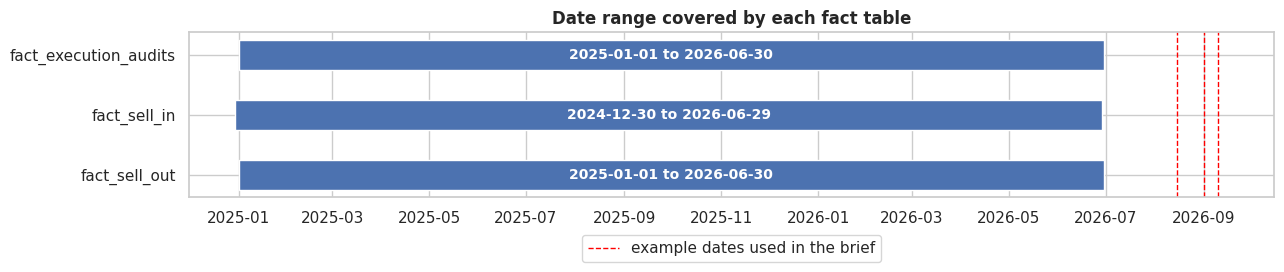

In [9]:
del si_price
fig, ax = plt.subplots(figsize=(13, 3))
facts = ['fact_sell_out', 'fact_sell_in', 'fact_execution_audits']
for i, n in enumerate(facts):
    d0, d1 = tables[n].date.min(), tables[n].date.max()
    ax.barh(i, (d1 - d0).days, left=d0, color='#4C72B0', height=0.5)
    ax.text(d0 + (d1 - d0) / 2, i, f'{d0.date()} to {d1.date()}', va='center', ha='center', fontsize=10, color='white', fontweight='bold')
for dt, lbl in [('2026-08-15', 'example dates used in the brief'), ('2026-09-01', None), ('2026-09-10', None)]:
    ax.axvline(pd.Timestamp(dt), color='red', ls='--', lw=1, label=lbl)
ax.set_yticks(range(len(facts))); ax.set_yticklabels(facts)
ax.set_xlim(pd.Timestamp('2024-12-01'), pd.Timestamp('2026-10-15'))
ax.set_title('Date range covered by each fact table'); ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.18))
plt.tight_layout(); plt.show()

All three tables cover the same 18 months. Sell-in starts on 30 Dec 2024, which is a Monday (first hint that invoices are weekly). The brief's example dates (red lines) fall *after* the data ends. This matters for the chatbot: when someone asks about "this week", the app has to treat **30 June 2026 as today**, not the real date.

### 3.6 The missing days problem
Quick math: 221 stores × ~20 SKUs × 546 days should give roughly 2.4M sell-out rows, but we only have 1.66M. So we checked which store-days actually have data.

In [10]:
store_days = sell_out[['store_id', 'date']].drop_duplicates()
all_days = pd.date_range(sell_out.date.min(), sell_out.date.max(), freq='D')
expected = len(stores) * len(all_days)
print(f'Store-days expected: {expected:,} | recorded: {len(store_days):,} | missing: {1 - len(store_days) / expected:.1%}')

assortment = sell_out[['store_id', 'sku_id']].drop_duplicates()
skus_per_store = assortment.groupby('store_id').sku_id.nunique()
rows_per_store_day = sell_out.groupby(['store_id', 'date']).size()
full_days = (rows_per_store_day.values == skus_per_store.reindex(rows_per_store_day.index.get_level_values('store_id')).values).mean()
print(f'Recorded store-days where every SKU of the store is present: {full_days:.1%}')

Store-days expected: 120,666 | recorded: 84,084 | missing: 30.3%
Recorded store-days where every SKU of the store is present: 100.0%


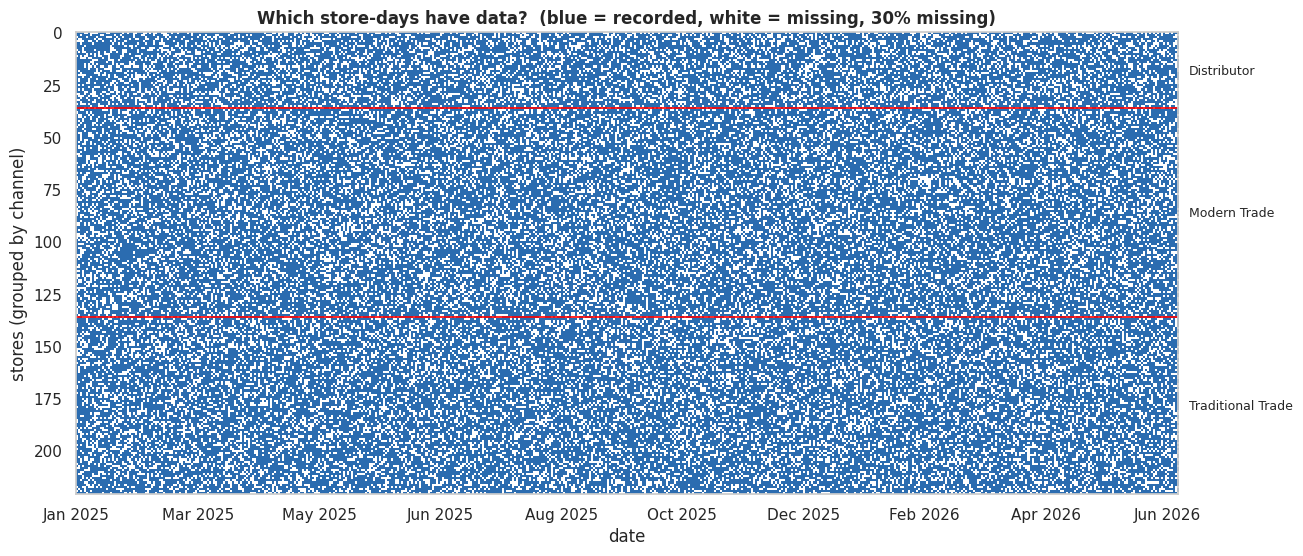

In [11]:
presence = (store_days.assign(v=1).pivot(index='store_id', columns='date', values='v')
            .reindex(columns=all_days).fillna(0))
presence = presence.reindex(stores.sort_values(['channel', 'store_id']).store_id)

fig, ax = plt.subplots(figsize=(15, 6))
ax.imshow(presence.values, aspect='auto', cmap=ListedColormap(['white', '#2b6cb0']), interpolation='nearest')
ax.grid(False)
ax.set_title(f'Which store-days have data?  (blue = recorded, white = missing, {1 - presence.values.mean():.0%} missing)')
ax.set_ylabel('stores (grouped by channel)'); ax.set_xlabel('date')
ticks = np.arange(0, len(all_days), 60)
ax.set_xticks(ticks); ax.set_xticklabels([all_days[i].strftime('%b %Y') for i in ticks])
ch_counts = stores.channel.value_counts().sort_index()
edges = ch_counts.cumsum().values
for e in edges[:-1]:
    ax.axhline(e - 0.5, color='red', lw=1.2)
for ch, s0, e in zip(ch_counts.index, np.r_[0, edges[:-1]], edges):
    ax.text(len(all_days) + 5, (s0 + e) / 2, ch, va='center', fontsize=9)
fig.subplots_adjust(right=0.86)
plt.show()

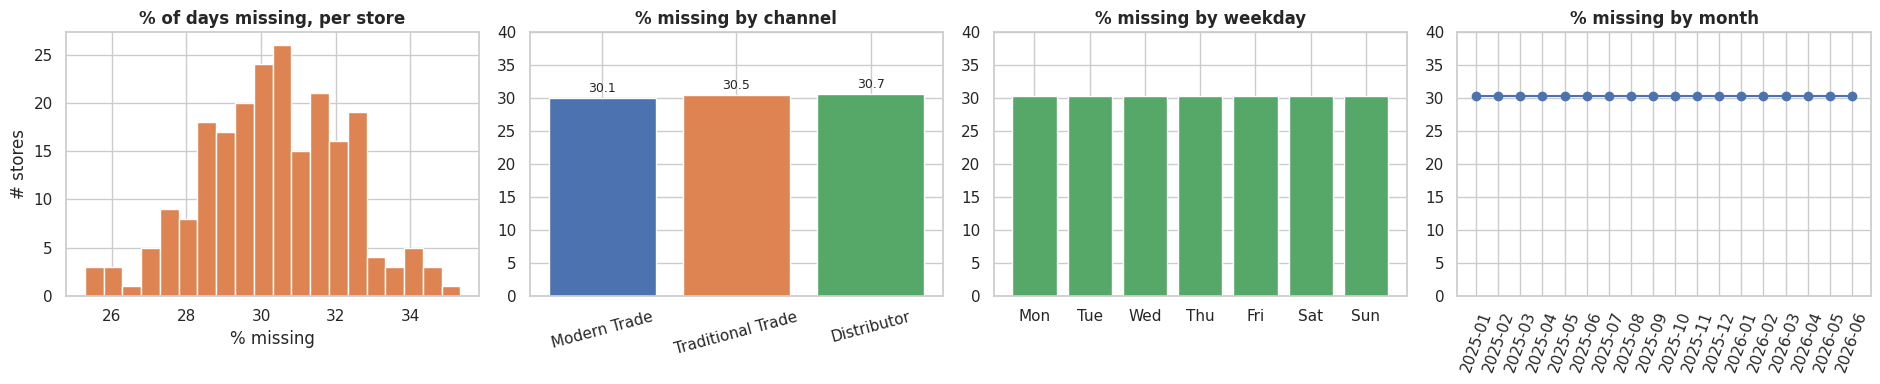

Missing per store: min 25.3% | median 30.4% | max 35.3%


In [12]:
missing_by_store = 1 - presence.mean(axis=1)
daily_presence = presence.mean(axis=0)
dow_missing = 1 - daily_presence.groupby(all_days.dayofweek).mean()
month_missing = 1 - daily_presence.groupby(all_days.to_period('M')).mean()
ch_missing = missing_by_store.groupby(stores.set_index('store_id').channel).mean().reindex(CH_ORDER)

fig, axes = plt.subplots(1, 4, figsize=(19, 4))
axes[0].hist(missing_by_store * 100, bins=20, color='#DD8452'); axes[0].set_title('% of days missing, per store')
axes[0].set_xlabel('% missing'); axes[0].set_ylabel('# stores')
axes[1].bar(ch_missing.index, ch_missing.values * 100, color=[CH_COL[c] for c in ch_missing.index])
axes[1].set_title('% missing by channel'); axes[1].set_ylim(0, 40); axes[1].tick_params(axis='x', rotation=15); label_bars(axes[1])
axes[2].bar(DAYS, dow_missing.values * 100, color='#55A868'); axes[2].set_title('% missing by weekday'); axes[2].set_ylim(0, 40)
axes[3].plot(month_missing.index.astype(str), month_missing.values * 100, marker='o')
axes[3].set_title('% missing by month'); axes[3].set_ylim(0, 40); axes[3].tick_params(axis='x', rotation=70)
plt.tight_layout(); plt.show()
print(f'Missing per store: min {missing_by_store.min():.1%} | median {missing_by_store.median():.1%} | max {missing_by_store.max():.1%}')

**What we found**
1. About **30% of store-days are missing**, and every store is missing roughly the same share (between ~25% and ~35%).
2. It's always the **whole day** for a store: when a day is recorded, all of the store's SKUs are there.
3. There's no pattern by channel, weekday or month. It looks like random noise added on purpose.

The obvious next question was whether anything *happened* on those missing days (sales we just can't see). The next check answers that.

### 3.7 Internal consistency: does the stock math add up?
If the data is realistic, then:

$$\text{stock}_{today} = \text{stock}_{yesterday} - \text{units sold}_{today} + \text{delivered}_{today}$$

So we can back out how many units must have been delivered. Negative deliveries would be impossible. We also split this by how many days passed since the previous recorded row, to see if stock drops more after a gap (which would mean sales happened on the missing days).

In [13]:
so = sell_out.sort_values(['store_id', 'sku_id', 'date']).reset_index(drop=True)
g = so.groupby(['store_id', 'sku_id'])
so['gap_days'] = g.date.diff().dt.days
so['prev_inv'] = g.inventory_level.shift()
so['delivered'] = so.inventory_level - (so.prev_inv - so.units_sold_daily)   # units that must have arrived

gap_check = (so.dropna(subset=['gap_days'])
               .assign(days_since_last_record=lambda d: d.gap_days.clip(upper=4).astype(int).astype(str).replace({'4': '4+'}))
               .groupby('days_since_last_record')
               .agg(rows=('delivered', 'size'),
                    stock_math_exact=('delivered', lambda x: (x == 0).mean()),
                    delivery_seen=('delivered', lambda x: (x > 0).mean()),
                    stock_dropped_more_than_sales=('delivered', lambda x: (x < 0).mean())))
display(gap_check.round(3))

print('Rows with negative deliveries (impossible):', int((so.delivered < 0).sum()))
pd.crosstab(so.is_out_of_stock, so.inventory_level == 0, rownames=['is_out_of_stock'], colnames=['inventory_level == 0'])

,rows,stock_math_exact,delivery_seen,stock_dropped_more_than_sales
days_since_last_record,,,,
1,1151526,0.940,0.060,0.0
2,349580,0.939,0.061,0.0
3,105665,0.940,0.060,0.0
4+,45630,0.937,0.063,0.0


Rows with negative deliveries (impossible): 0


inventory_level == 0,False,True
is_out_of_stock,,
False,1557803,0
True,0,98953


**What we found**
1. The stock math is **exact**: zero impossible rows, and about 6% of rows have a delivery.
2. After a gap of 2, 3 or 4+ days, stock **never** drops by more than what was sold on the recorded day, and deliveries show up at the same ~6% rate. So on missing days **nothing happened**: no sales and no deliveries. From here on we treat missing days as zero-sales days with unchanged stock.
3. `is_out_of_stock` is exactly the same as `inventory_level == 0`. So the OOS flag really means "stock at the *end* of the day is zero", which is why some OOS days still have a few units sold.

### 3.8 Outliers
We used the standard 1.5 × IQR rule on the main numeric columns:

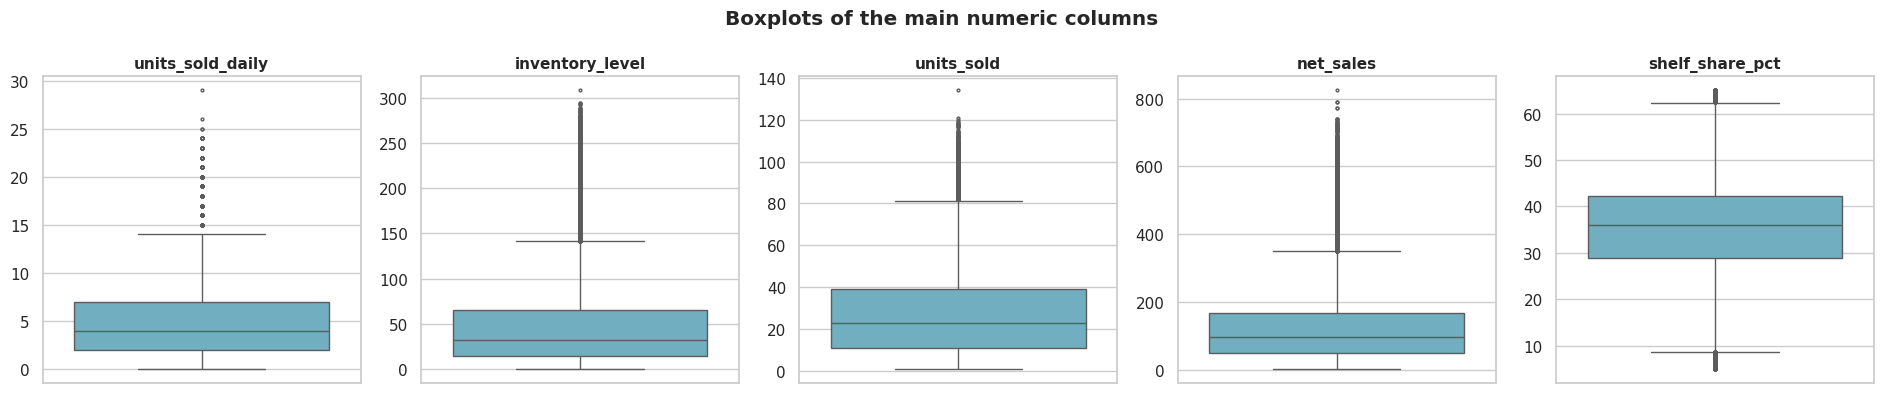

,column,min,median,max,upper_fence,outlier_%
0,fact_sell_out.units_sold_daily,0.00,4.00,32.0,14.500,1.95
1,fact_sell_out.inventory_level,0.00,32.00,315.0,139.000,4.35
2,fact_sell_in.units_sold,1.00,23.00,134.0,81.000,1.23
3,fact_sell_in.net_sales,2.29,98.02,843.4,349.125,3.05
4,fact_execution_audits.shelf_share_pct,5.00,36.06,65.0,62.385,0.46


Where do the "outlier" sales days (> 14.5 units) come from? {'Tier 1': 98.9, 'Tier 2': 1.1}


In [14]:
num_cols = [('fact_sell_out', 'units_sold_daily'), ('fact_sell_out', 'inventory_level'),
            ('fact_sell_in', 'units_sold'), ('fact_sell_in', 'net_sales'), ('fact_execution_audits', 'shelf_share_pct')]
rows = []
fig, axes = plt.subplots(1, 5, figsize=(19, 4))
for ax, (t, c) in zip(axes, num_cols):
    x = tables[t][c]
    q1, q3 = x.quantile([.25, .75]); iqr = q3 - q1
    rows.append({'column': f'{t}.{c}', 'min': x.min(), 'median': x.median(), 'max': x.max(),
                 'upper_fence': q3 + 1.5 * iqr, 'outlier_%': round(((x < q1 - 1.5 * iqr) | (x > q3 + 1.5 * iqr)).mean() * 100, 2)})
    sns.boxplot(y=x.sample(200_000, random_state=0) if len(x) > 200_000 else x, ax=ax, color='#64B5CD', fliersize=2)
    ax.set_title(c, fontsize=11); ax.set_ylabel('')
plt.suptitle('Boxplots of the main numeric columns', fontweight='bold'); plt.tight_layout(); plt.show()
outlier_table = pd.DataFrame(rows)
display(outlier_table)

fence = rows[0]['upper_fence']
high = sell_out[sell_out.units_sold_daily > fence].merge(stores[['store_id', 'segment_tier']], on='store_id')
print(f'Where do the "outlier" sales days (> {fence:.1f} units) come from?',
      (high.segment_tier.value_counts(normalize=True) * 100).round(1).to_dict())
del high

Only 0.5–4% of values get flagged, and when we looked at *where* the high sales days come from, basically all of them are **Tier 1 stores**. So these aren't errors, they're just big stores. We're keeping them.

### 3.9 Data quality summary

| Check | Result | What we'll do |
|---|---|---|
| Nulls, duplicates, keys | All clean | Nothing |
| Referential integrity | All IDs match | Nothing |
| Value ranges | All valid | Nothing |
| Extra `state` column | Not in the brief | Use it for state-level views |
| Date range | Ends 30 Jun 2026; brief examples use later dates | Treat 30 Jun 2026 as "today" in the app |
| ~30% store-days missing | Whole days, random, nothing happens on them | Treat as zero sales + unchanged stock; ask Dr. Masse |
| Stock math | Exact | We can back out deliveries |
| Outliers | Real Tier 1 volume | Keep them |

## 4. Univariate analysis
Now looking at each variable on its own. First we join the store and product info onto sell-out once, so we don't have to keep merging later. We also add `sales_value` = units × list price, as a simple way to put a dollar value on sales.

In [15]:
sof = (so[['date', 'store_id', 'sku_id', 'units_sold_daily', 'inventory_level', 'is_out_of_stock']]
       .merge(stores[['store_id', 'channel', 'region', 'state', 'segment_tier']], on='store_id')
       .merge(products[['sku_id', 'product_name', 'category', 'brand', 'is_msl', 'list_price']], on='sku_id'))
sof['sales_value'] = sof.units_sold_daily * sof.list_price
si = (sell_in.merge(stores[['store_id', 'channel', 'region', 'segment_tier']], on='store_id')
             .merge(products[['sku_id', 'category', 'list_price', 'unit_cost']], on='sku_id'))
au = audits.merge(stores[['store_id', 'channel', 'region', 'segment_tier']], on='store_id')
print(sof.shape, si.shape, au.shape)

(1656756, 16) (277969, 12) (207020, 10)


### 4.1 Stores

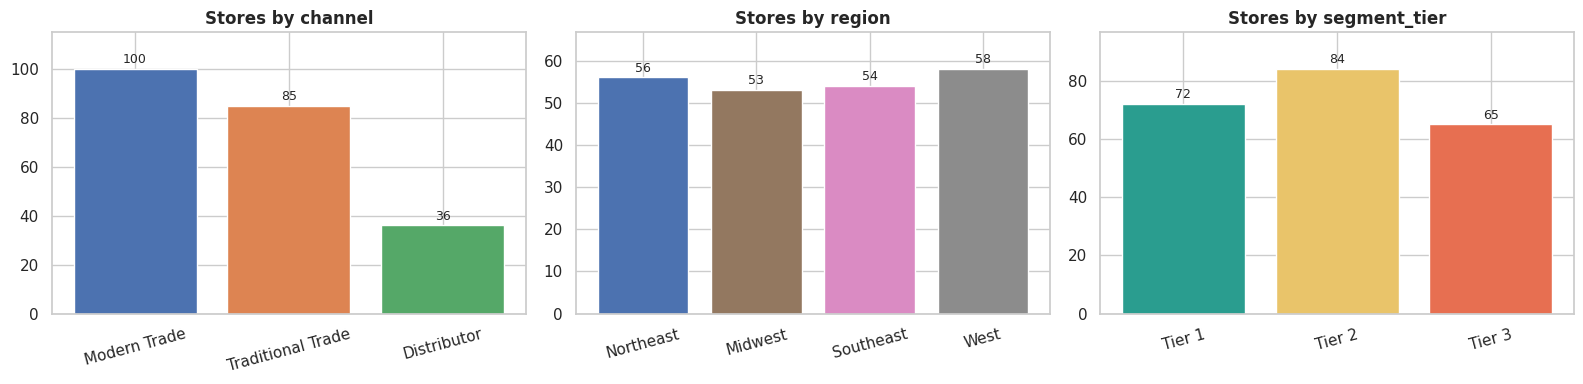

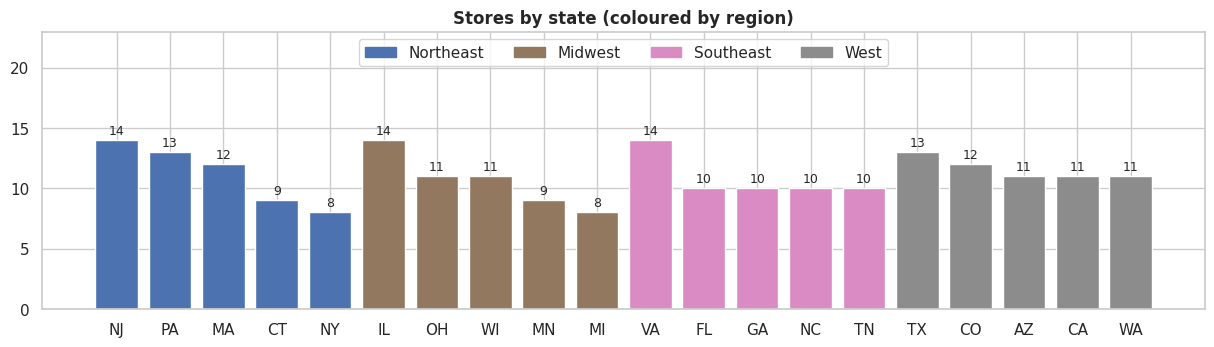

221 stores | 20 states | 62 cities


In [16]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col, order, pal in zip(axes, ['channel', 'region', 'segment_tier'], [CH_ORDER, REGION_ORDER, TIER_ORDER], [CH_COL, REG_COL, TIER_COL]):
    cnt = stores[col].value_counts().reindex(order)
    ax.bar(cnt.index, cnt.values, color=[pal[x] for x in cnt.index])
    label_bars(ax, '{:.0f}'); ax.set_title(f'Stores by {col}'); ax.tick_params(axis='x', rotation=15)
    ax.set_ylim(0, cnt.max() * 1.15)
plt.tight_layout(); plt.show()

by_state = stores.groupby(['region', 'state']).size().rename('stores').reset_index()
by_state['region'] = pd.Categorical(by_state.region, REGION_ORDER)
by_state = by_state.sort_values(['region', 'stores'], ascending=[True, False])
fig, ax = plt.subplots(figsize=(15, 3.6))
ax.bar(by_state.state, by_state.stores, color=[REG_COL[r] for r in by_state.region])
label_bars(ax, '{:.0f}')
ax.legend(handles=[Patch(color=REG_COL[r], label=r) for r in REGION_ORDER], ncol=4, loc='upper center')
ax.set_title('Stores by state (coloured by region)'); ax.set_ylim(0, by_state.stores.max() + 9)
plt.show()
print(f"{len(stores)} stores | {stores.state.nunique()} states | {stores.city.nunique()} cities")

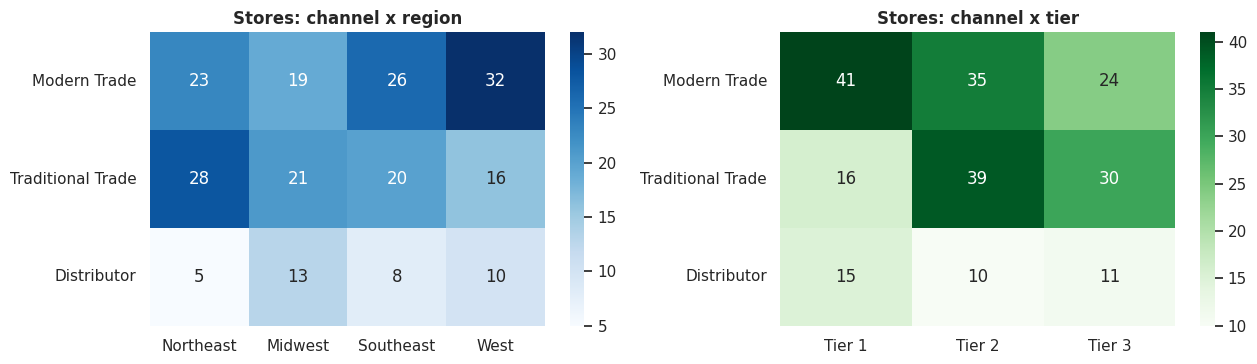

,store_id,store_name,channel,region,state,segment_tier,city
4,STR-0005,Central Supply Albany,Distributor,Northeast,NY,Tier 2,Albany
7,STR-0008,Buffalo Depot #8,Distributor,Northeast,NY,Tier 3,Buffalo
10,STR-0011,Pittsburgh Distribution Co. #11,Distributor,Northeast,PA,Tier 2,Pittsburgh
43,STR-0044,Northeast Wholesale #44,Distributor,Northeast,NJ,Tier 1,Trenton
49,STR-0050,Northeast Wholesale #50,Distributor,Northeast,CT,Tier 3,Bridgeport


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
heatmap(pd.crosstab(stores.channel, stores.region).reindex(CH_ORDER)[REGION_ORDER], annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title('Stores: channel x region'); axes[0].set_xlabel(''); axes[0].set_ylabel('')
heatmap(pd.crosstab(stores.channel, stores.segment_tier).reindex(CH_ORDER)[TIER_ORDER], annot=True, fmt='d', cmap='Greens', ax=axes[1])
axes[1].set_title('Stores: channel x tier'); axes[1].set_xlabel(''); axes[1].set_ylabel('')
plt.tight_layout(); plt.show()
stores[stores.channel == 'Distributor'].head(5)

**Notes**
1. 221 stores: 100 Modern Trade, 85 Traditional Trade, 36 Distributors.
2. The 4 regions are balanced (53–58 stores each), with 5 states per region and 62 cities in total. Everything is in the US, even though Dr. Masse described Latin American neighborhood shops in the meeting.
3. Modern Trade has the most Tier 1 stores; Traditional Trade is mostly Tier 2 and 3.
4. The "Distributor" stores have names like *Bulk Supply*, *Wholesale* and *Distribution Co.*, but they still have daily consumer sell-out like a normal store. We're not sure how Globant wants these treated (Dr. Masse also only mentioned two channels).

### 4.2 Products

,sku_id,product_name,category,brand,is_msl,unit_cost,list_price,margin_on_list_pct
0,SKU-1001,Marvel Power Clean Lemon 1L,Surface Cleaners,Marvel Clean,True,2.10,4.50,53.3
1,SKU-1002,Marvel Power Clean Original 1L,Surface Cleaners,Marvel Clean,True,2.05,4.40,53.4
2,SKU-1003,Marvel Power Clean Lavender 750ml,Surface Cleaners,Marvel Clean,False,1.85,3.90,52.6
3,SKU-1004,Marvel Heavy-Duty Degreaser 1L,Surface Cleaners,Marvel Pro,True,2.80,5.80,51.7
4,SKU-1005,Marvel Heavy-Duty Degreaser 500ml,Surface Cleaners,Marvel Pro,False,1.65,3.50,52.9
5,SKU-1006,Marvel Glass & Surface Spray 32oz,Surface Cleaners,Marvel Bright,True,1.95,4.20,53.6
6,SKU-1007,Marvel Bathroom Foam Cleaner 20oz,Surface Cleaners,Marvel Clean,False,1.75,3.80,53.9
7,SKU-1008,Marvel Multi-Surface Wipes 75ct,Surface Cleaners,Marvel Clean,True,2.45,5.10,52.0
8,SKU-1009,Marvel Dish Soap Citrus 28oz,Dishwashing,Marvel Fresh,True,1.50,3.20,53.1
9,SKU-1010,Marvel Dish Soap Original 28oz,Dishwashing,Marvel Fresh,True,1.48,3.15,53.0


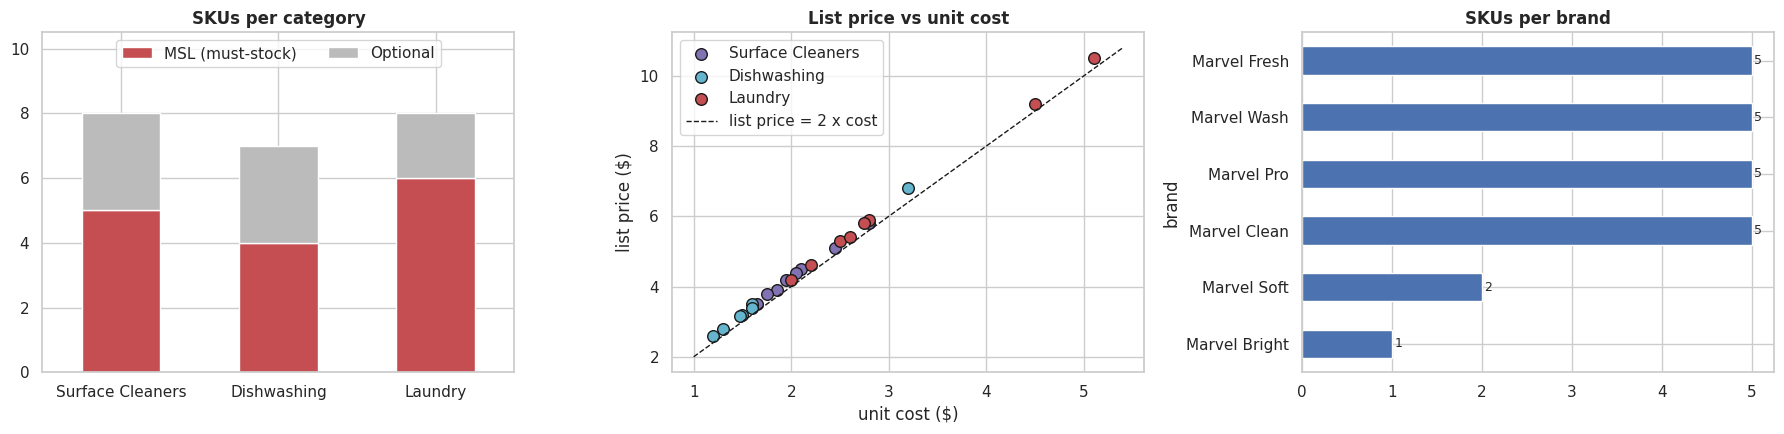

Stores that carry all 15 MSL SKUs: 221 of 221
SKUs carried per store: min 15 | max 23


In [18]:
display(products.assign(margin_on_list_pct=lambda d: ((d.list_price - d.unit_cost) / d.list_price * 100).round(1)))

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
ct = pd.crosstab(products.category, products.is_msl).reindex(index=CAT_ORDER, columns=[True, False])
ct.columns = ['MSL (must-stock)', 'Optional']
ct.plot.bar(stacked=True, ax=axes[0], color=['#C44E52', '#BBBBBB'], rot=0)
axes[0].set_title('SKUs per category'); axes[0].set_xlabel(''); axes[0].set_ylim(0, 10.5); axes[0].legend(ncol=2, loc='upper center')
for cat in CAT_ORDER:
    sub = products[products.category == cat]
    axes[1].scatter(sub.unit_cost, sub.list_price, s=70, color=CAT_COL[cat], label=cat, edgecolor='k')
x = np.linspace(1, 5.4, 10)
axes[1].plot(x, 2 * x, 'k--', lw=1, label='list price = 2 x cost')
axes[1].set_xlabel('unit cost ($)'); axes[1].set_ylabel('list price ($)'); axes[1].set_title('List price vs unit cost'); axes[1].legend()
products.brand.value_counts().sort_values().plot.barh(ax=axes[2], color='#4C72B0')
axes[2].set_title('SKUs per brand'); label_bars(axes[2], '{:.0f}')
plt.tight_layout(); plt.show()

per_store = assortment.merge(products[['sku_id', 'is_msl']], on='sku_id').groupby('store_id').agg(skus=('sku_id', 'nunique'), msl=('is_msl', 'sum'))
print('Stores that carry all 15 MSL SKUs:', (per_store.msl == 15).sum(), 'of', len(per_store))
print('SKUs carried per store: min', per_store.skus.min(), '| max', per_store.skus.max())

**Notes**
1. 23 SKUs, 3 categories, 6 brands. 15 SKUs are MSL (must-stock), and Laundry has the most (6 of 8).
2. Every SKU is priced at roughly **2× its cost** (margin on list price 51–54%), so pricing is very uniform. Laundry items are the most expensive.
3. Every store carries all 15 MSL SKUs. The optional ones vary, so stores carry between 15 and 23 SKUs.

### 4.3 Daily sales (sell-out)

{'count': 1656756.0, 'mean': 4.71, 'std': 3.86, 'min': 0.0, '25%': 2.0, '50%': 4.0, '75%': 7.0, 'max': 32.0}
Share of store-SKU-days with zero sales: 11.8%


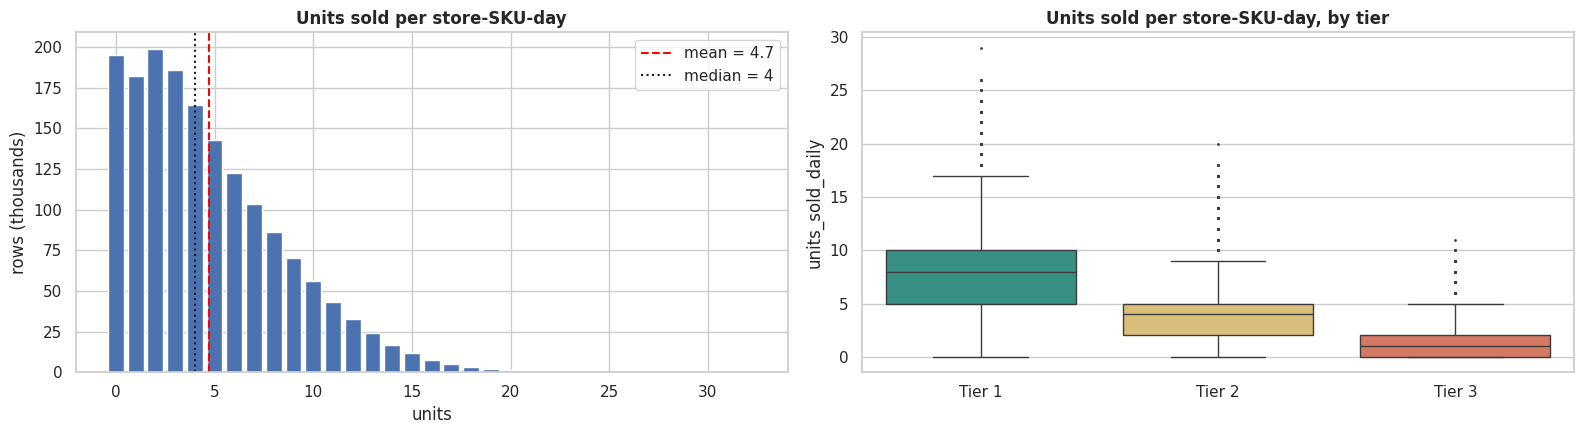

In [19]:
u = sof.units_sold_daily
print(u.describe().round(2).to_dict())
print(f'Share of store-SKU-days with zero sales: {(u == 0).mean():.1%}')

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
vc = u.value_counts().sort_index()
axes[0].bar(vc.index, vc.values / 1e3, color='#4C72B0')
axes[0].axvline(u.mean(), color='red', ls='--', label=f'mean = {u.mean():.1f}')
axes[0].axvline(u.median(), color='k', ls=':', label=f'median = {u.median():.0f}')
axes[0].set_title('Units sold per store-SKU-day'); axes[0].set_xlabel('units'); axes[0].set_ylabel('rows (thousands)'); axes[0].legend()
samp = sof.sample(300_000, random_state=1)
sns.boxplot(data=samp, x='segment_tier', y='units_sold_daily', order=TIER_ORDER, hue='segment_tier', palette=TIER_COL, legend=False, ax=axes[1], fliersize=1)
axes[1].set_title('Units sold per store-SKU-day, by tier'); axes[1].set_xlabel('')
plt.tight_layout(); plt.show()

**Notes:** Daily sales per SKU are small numbers (median 4 units, max 32) and right-skewed, which is typical for count data. About 12% of store-SKU-days sell nothing. The split by tier is huge: Tier 1 stores sell several times more than Tier 3, and this keeps showing up in the rest of the notebook.

### 4.4 Stock levels

{'count': 1656756.0, 'mean': 45.5, 'std': 42.8, 'min': 0.0, '25%': 14.0, '50%': 32.0, '75%': 64.0, 'max': 315.0}


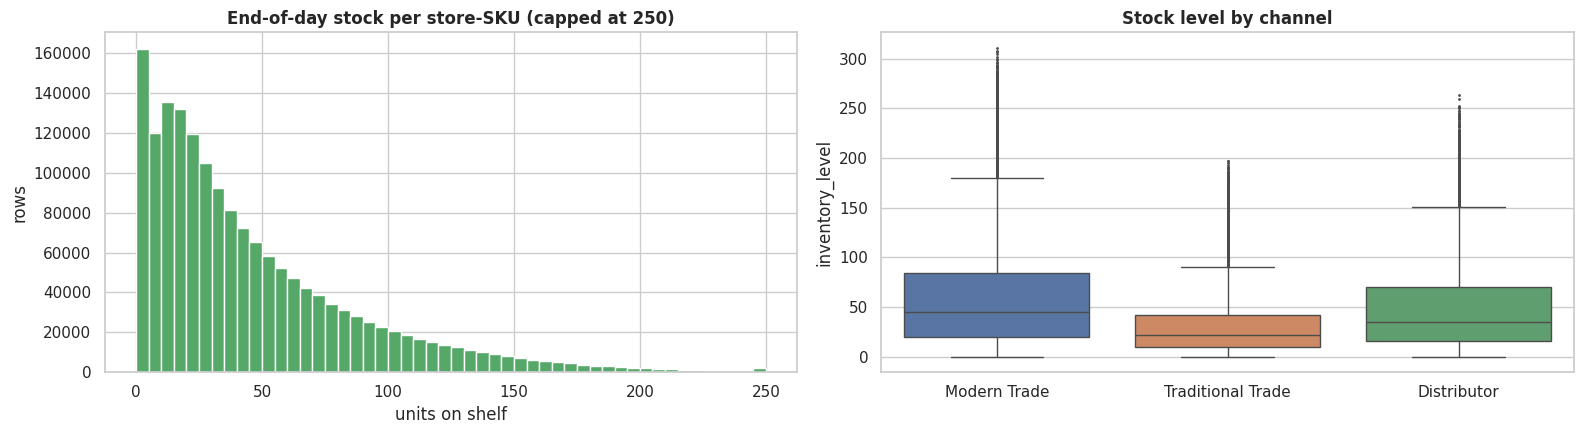

In [20]:
inv = sof.inventory_level
print(inv.describe().round(1).to_dict())
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
axes[0].hist(inv.clip(upper=250), bins=50, color='#55A868')
axes[0].set_title('End-of-day stock per store-SKU (capped at 250)'); axes[0].set_xlabel('units on shelf'); axes[0].set_ylabel('rows')
sns.boxplot(data=samp, x='channel', y='inventory_level', order=CH_ORDER, hue='channel', palette=CH_COL, legend=False, ax=axes[1], fliersize=1)
axes[1].set_title('Stock level by channel'); axes[1].set_xlabel('')
plt.tight_layout(); plt.show()

**Notes:** Stock is also right-skewed (median 32 units, max 315). There's a visible spike at 0, which is the out-of-stock days. Traditional Trade stores hold much less stock than Modern Trade, which makes sense for small shops.

### 4.5 Sell-in (invoices)

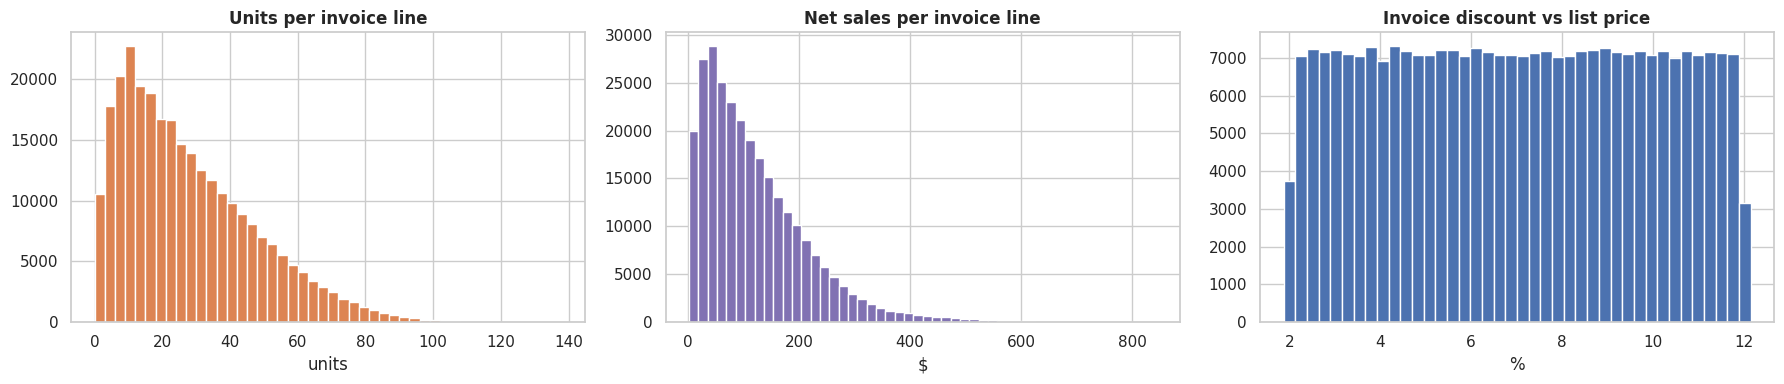

,units_sold,net_sales,discount_%
count,277969.00,277969.00,277969.00
mean,27.19,121.19,7.00
std,19.73,96.34,2.89
min,1.00,2.29,1.88
25%,11.00,48.70,4.50
50%,23.00,98.02,6.99
75%,39.00,168.87,9.50
max,134.00,843.40,12.14


In [21]:
si['unit_price'] = si.net_sales / si.units_sold
si['discount_%'] = (1 - si.unit_price / si.list_price) * 100
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
axes[0].hist(si.units_sold, bins=range(0, 140, 3), color='#DD8452'); axes[0].set_title('Units per invoice line'); axes[0].set_xlabel('units')
axes[1].hist(si.net_sales, bins=50, color='#8172B3'); axes[1].set_title('Net sales per invoice line'); axes[1].set_xlabel('$')
axes[2].hist(si['discount_%'], bins=40, color='#4C72B0'); axes[2].set_title('Invoice discount vs list price'); axes[2].set_xlabel('%')
plt.tight_layout(); plt.show()
si[['units_sold', 'net_sales', 'discount_%']].describe().round(2)

**Notes:** A typical invoice line is ~23 units and ~$98. The discount vs list price is spread almost **perfectly evenly between 2% and 12%**, which looks more like a random number than a real commercial decision. We come back to this in section 8.4.

### 4.6 Audit metrics

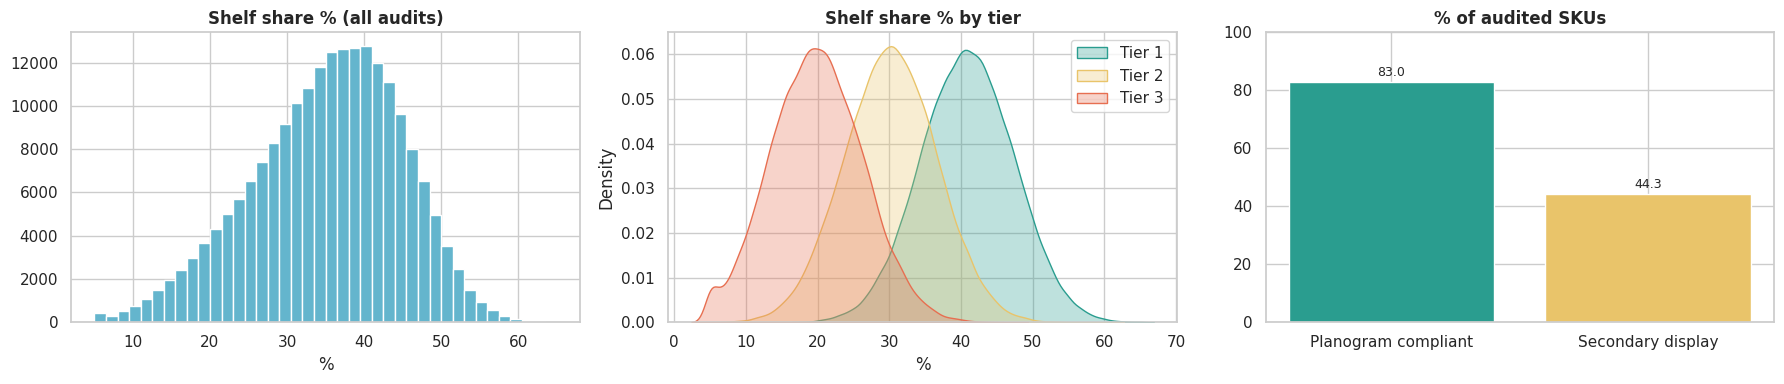

{'count': 207020.0, 'mean': 35.2, 'std': 9.7, 'min': 5.0, '25%': 28.8, '50%': 36.1, '75%': 42.2, 'max': 65.0}


In [22]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
axes[0].hist(au.shelf_share_pct, bins=40, color='#64B5CD'); axes[0].set_title('Shelf share % (all audits)'); axes[0].set_xlabel('%')
for t in TIER_ORDER:
    sns.kdeplot(au.loc[au.segment_tier == t, 'shelf_share_pct'], ax=axes[1], color=TIER_COL[t], label=t, fill=True, alpha=0.3)
axes[1].set_title('Shelf share % by tier'); axes[1].legend(); axes[1].set_xlabel('%')
rates = pd.Series({'Planogram compliant': au.planogram_compliance.mean() * 100, 'Secondary display': au.secondary_display.mean() * 100})
axes[2].bar(rates.index, rates.values, color=['#2A9D8F', '#E9C46A']); axes[2].set_ylim(0, 100); label_bars(axes[2])
axes[2].set_title('% of audited SKUs')
plt.tight_layout(); plt.show()
print(au.shelf_share_pct.describe().round(1).to_dict())

**Notes:** Average shelf share is ~35% and looks roughly bell-shaped overall. But splitting by tier shows it's really **three separate humps**: Tier 3 stores sit around 20% and Tier 1 around 41%. Across all audits, 83% of SKUs follow the planogram and 44% have a secondary display.

## 5. Bivariate and multivariate analysis

### 5.1 Store performance by channel, tier and region
Each dot is one store (its average units per SKU per recorded day).

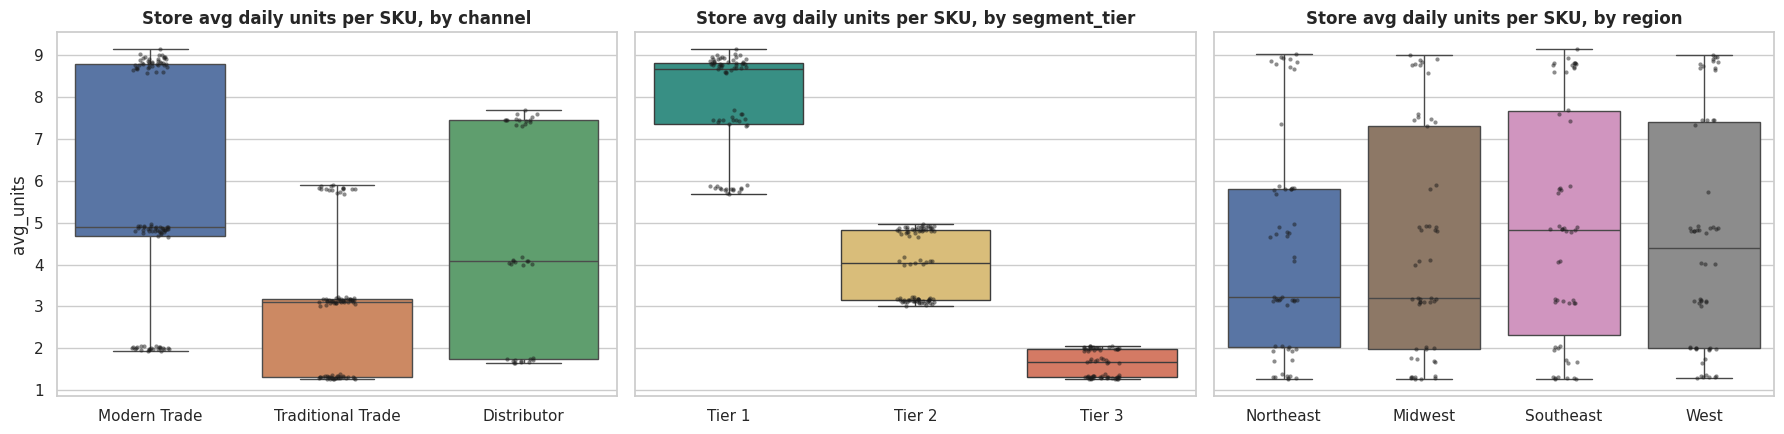

,avg_units
segment_tier,
Tier 1,8.67
Tier 2,4.03
Tier 3,1.66


In [23]:
store_perf = (sof.groupby('store_id').agg(avg_units=('units_sold_daily', 'mean'), sales_value=('sales_value', 'sum'),
                                         oos_rate=('is_out_of_stock', 'mean'))
                 .join(stores.set_index('store_id')).reset_index())
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5), sharey=True)
for ax, col, order, pal in zip(axes, ['channel', 'segment_tier', 'region'], [CH_ORDER, TIER_ORDER, REGION_ORDER], [CH_COL, TIER_COL, REG_COL]):
    sns.boxplot(data=store_perf, x=col, y='avg_units', order=order, hue=col, palette=pal, legend=False, ax=ax, showfliers=False)
    sns.stripplot(data=store_perf, x=col, y='avg_units', order=order, color='k', size=3, alpha=0.5, ax=ax)
    ax.set_title(f'Store avg daily units per SKU, by {col}'); ax.set_xlabel('')
plt.tight_layout(); plt.show()
store_perf.groupby('segment_tier').avg_units.median().round(2)

**Notes:** Tier is by far the strongest split: the median Tier 1 store sells ~8.7 units per SKU per day vs ~1.7 for Tier 3, about 5×. Channel matters a bit (Traditional Trade is lower, but it's also mostly Tier 2/3). Region barely matters at all.

Something else jumped out at us: the dots stack up at just a few levels instead of being spread out. Stores with the same tier and channel behave almost identically. That's probably how the synthetic data was generated, and it means individual stores don't have much "personality" for a model to learn beyond their tier and channel.

### 5.2 Where the money comes from

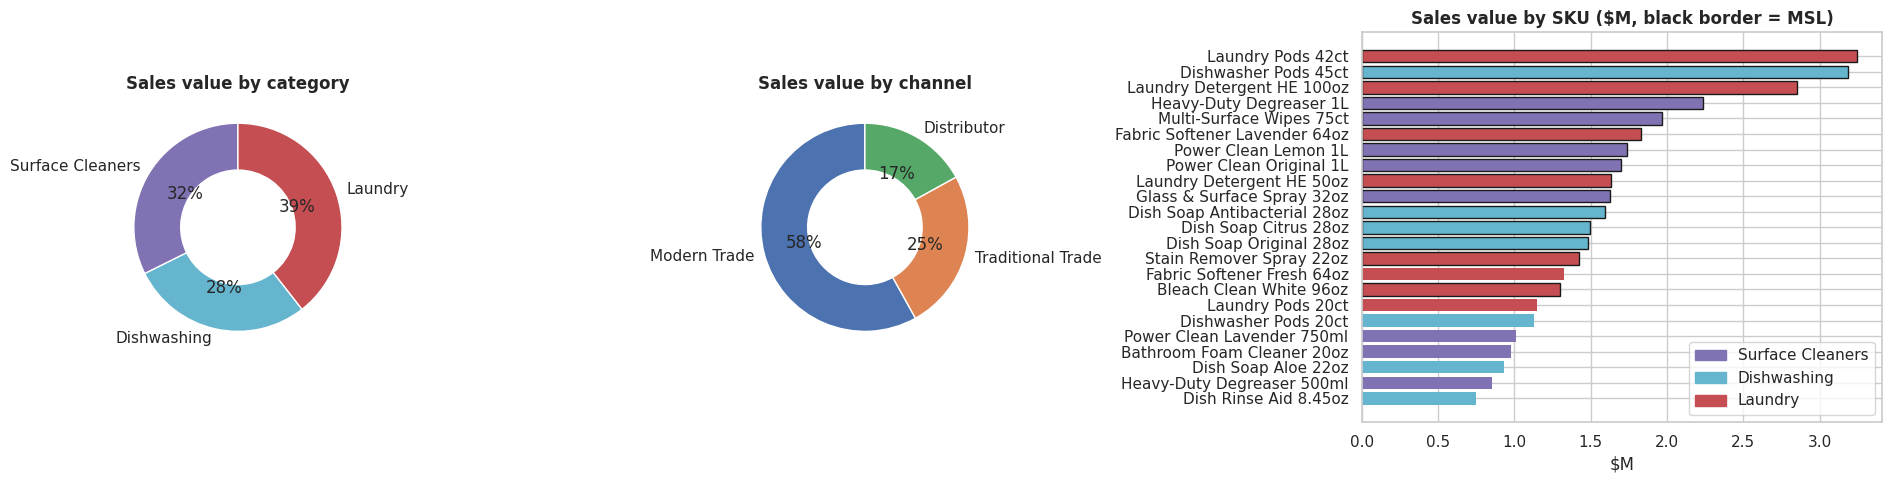

MSL SKUs make up 78% of sales value


In [24]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5), gridspec_kw={'width_ratios': [1, 1, 2]})
for ax, col, order, pal in zip(axes[:2], ['category', 'channel'], [CAT_ORDER, CH_ORDER], [CAT_COL, CH_COL]):
    share = sof.groupby(col).sales_value.sum().reindex(order)
    ax.pie(share, labels=share.index, autopct='%1.0f%%', colors=[pal[x] for x in share.index],
           wedgeprops=dict(width=0.45, edgecolor='w'), startangle=90)
    ax.set_title(f'Sales value by {col}')
sku_val = sof.groupby(['sku_id', 'product_name', 'category', 'is_msl']).sales_value.sum().reset_index().sort_values('sales_value')
axes[2].barh(sku_val.product_name.str.replace('Marvel ', ''), sku_val.sales_value / 1e6,
             color=[CAT_COL[c] for c in sku_val.category], edgecolor=['k' if m else 'none' for m in sku_val.is_msl])
axes[2].set_title('Sales value by SKU ($M, black border = MSL)'); axes[2].set_xlabel('$M')
axes[2].legend(handles=[Patch(color=CAT_COL[c], label=c) for c in CAT_ORDER], loc='lower right')
plt.tight_layout(); plt.show()
msl_share = sof.groupby('is_msl').sales_value.sum()
print(f"MSL SKUs make up {msl_share[True] / msl_share.sum():.0%} of sales value")

**Notes:** Laundry is the biggest category by value (~39%), mostly because its products are pricier. Modern Trade brings in ~58% of sales value. The top SKUs are the big-pack items (Laundry Pods 42ct, Dishwasher Pods 45ct, Laundry Detergent HE 100oz), and the 15 MSL SKUs make up ~78% of sales value, which makes sense for "must-stock" products.

### 5.3 How concentrated are sales? (Pareto)

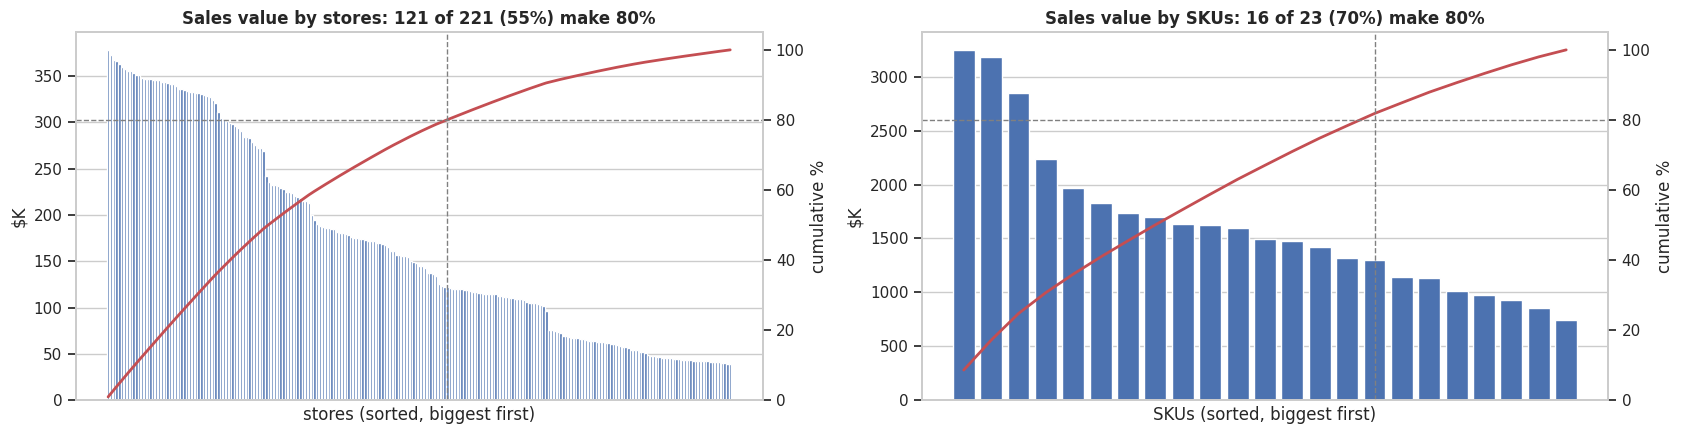

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(17, 4.5))
for ax, key_col, label in [(axes[0], 'store_id', 'stores'), (axes[1], 'sku_id', 'SKUs')]:
    s = sof.groupby(key_col).sales_value.sum().sort_values(ascending=False)
    cum = s.cumsum() / s.sum() * 100
    n80 = int((cum < 80).sum() + 1)
    ax.bar(range(len(s)), s.values / 1e3, color='#4C72B0')
    ax2 = ax.twinx(); ax2.plot(range(len(s)), cum.values, color='#C44E52', lw=2); ax2.set_ylim(0, 105); ax2.grid(False)
    ax2.axhline(80, color='grey', ls='--', lw=1); ax2.axvline(n80 - 1, color='grey', ls='--', lw=1)
    ax.set_title(f'Sales value by {label}: {n80} of {len(s)} ({n80 / len(s):.0%}) make 80%')
    ax.set_xlabel(f'{label} (sorted, biggest first)'); ax.set_ylabel('$K'); ax2.set_ylabel('cumulative %'); ax.set_xticks([])
plt.tight_layout(); plt.show()

**Notes:** Sales are *not* very concentrated. It takes ~55% of stores (121 of 221) and 16 of the 23 SKUs to make 80% of the value, so there's no classic 80/20 here. For the store visit ranking this means we can't just focus on a handful of big stores; risk needs to drive the ranking, not only size.

### 5.4 Geography

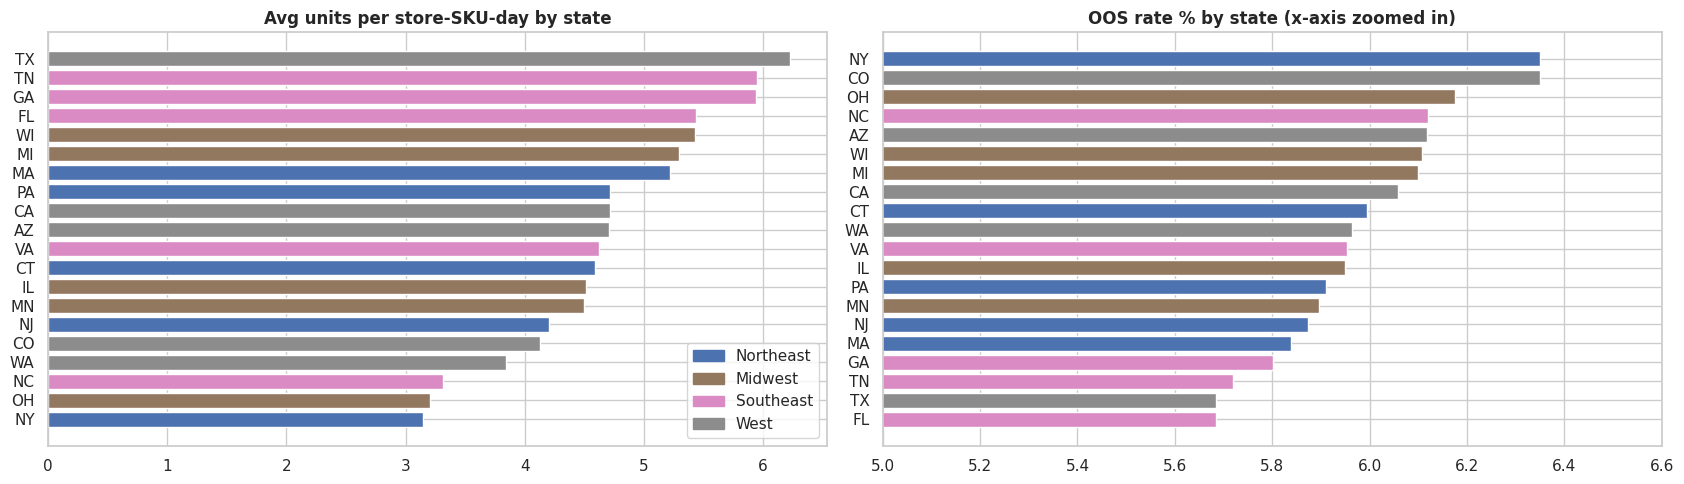

In [26]:
st = (sof.groupby(['state', 'region']).agg(avg_units=('units_sold_daily', 'mean'), oos_rate=('is_out_of_stock', 'mean'))
         .reset_index())
fig, axes = plt.subplots(1, 2, figsize=(17, 5))
for ax, col, title, mult in [(axes[0], 'avg_units', 'Avg units per store-SKU-day by state', 1),
                             (axes[1], 'oos_rate', 'OOS rate % by state (x-axis zoomed in)', 100)]:
    d = st.sort_values(col)
    ax.barh(d.state, d[col] * mult, color=[REG_COL[r] for r in d.region])
    ax.set_title(title)
axes[1].set_xlim(5, 6.6)
axes[0].legend(handles=[Patch(color=REG_COL[r], label=r) for r in REGION_ORDER], loc='lower right')
plt.tight_layout(); plt.show()

**Notes:** States differ in sales per SKU (NY, OH and NC are lowest), but that's mostly their tier mix. OOS by state only ranges from ~5.7% to ~6.4%. No region stands out, so a map in the dashboard would be nice to have, but it won't tell a big story.

### 5.5 Correlations (store-SKU level)
To look at many variables together, we summarised everything to one row per store-SKU pair (4,355 pairs) and built a correlation matrix. We turned tier into a number (1, 2, 3) so it could be included.

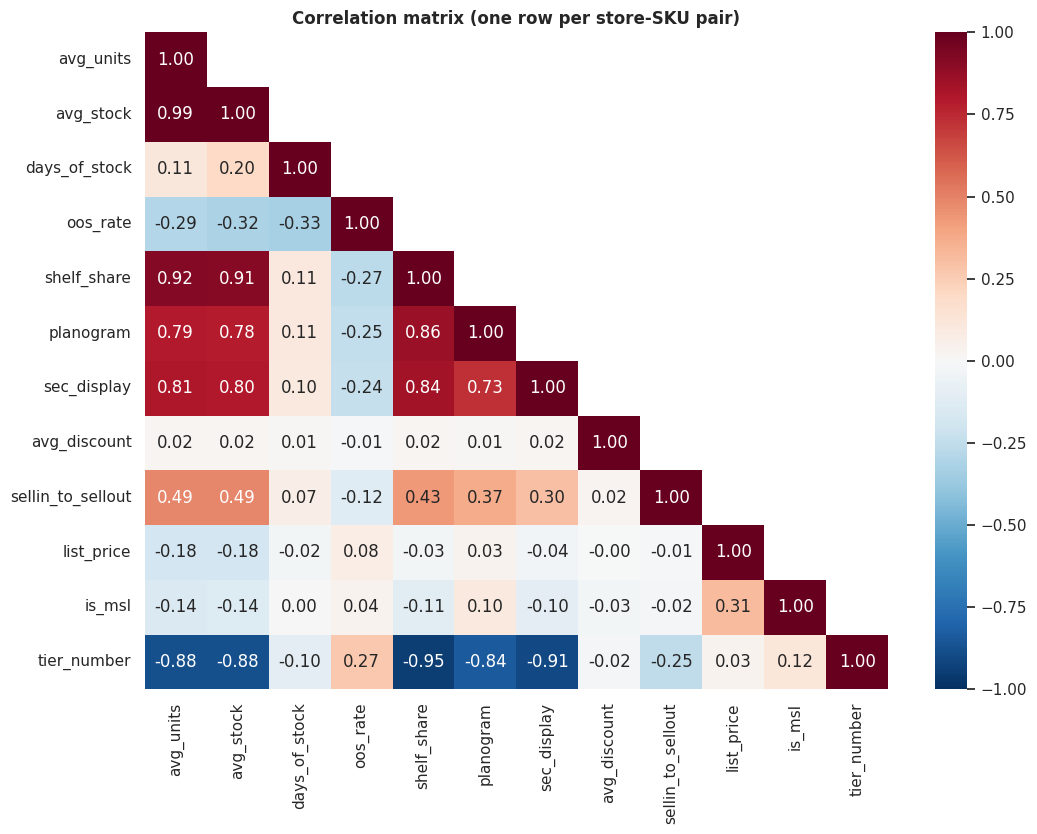

In [27]:
k = ['store_id', 'sku_id']
pair = (so.groupby(k).agg(avg_units=('units_sold_daily', 'mean'), avg_stock=('inventory_level', 'mean'),
                          oos_rate=('is_out_of_stock', 'mean'), total_units=('units_sold_daily', 'sum'))
          .join(si.groupby(k).agg(avg_discount=('discount_%', 'mean'), sellin_units=('units_sold', 'sum')))
          .join(audits.groupby(k).agg(shelf_share=('shelf_share_pct', 'mean'), planogram=('planogram_compliance', 'mean'),
                                      sec_display=('secondary_display', 'mean')))
          .reset_index().merge(stores[['store_id', 'segment_tier']], on='store_id')
          .merge(products[['sku_id', 'list_price', 'is_msl']], on='sku_id'))
pair['days_of_stock'] = pair.avg_stock / pair.avg_units
pair['sellin_to_sellout'] = pair.sellin_units / pair.total_units
pair['tier_number'] = pair.segment_tier.str[-1].astype(int)
pair['is_msl'] = pair.is_msl.astype(int)
cols = ['avg_units', 'avg_stock', 'days_of_stock', 'oos_rate', 'shelf_share', 'planogram', 'sec_display',
        'avg_discount', 'sellin_to_sellout', 'list_price', 'is_msl', 'tier_number']
corr = pair[cols].corr()
fig, ax = plt.subplots(figsize=(11, 8.5))
heatmap(corr, mask=np.triu(np.ones_like(corr, dtype=bool), 1), annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title('Correlation matrix (one row per store-SKU pair)')
plt.tight_layout(); plt.show()

**Notes** (this was one of the most useful charts for us)
1. **Tier drives almost everything.** `tier_number` correlates −0.88 with sales, −0.95 with shelf share, −0.84 with planogram and −0.91 with secondary display. Bigger stores sell more *and* execute better.
2. Stock is sized to sales (0.99 with avg units), so stores basically hold "X days' worth" of product.
3. OOS rate is most related to **days of stock** (−0.33) and tier (+0.27). Nothing else explains it strongly.
4. **Discount is related to nothing** (all ~0.0), another sign that discounts in this data are random.
5. Shelf share and sales look strongly linked (0.92), but that could just be tier in disguise. We check this properly in section 8.5.

## 6. Time series analysis
Because ~30% of days are missing at random, we use **average units per recorded store-SKU-day** instead of raw totals. Otherwise the totals would jump around just because fewer stores reported on some days.

### 6.1 Overall trend

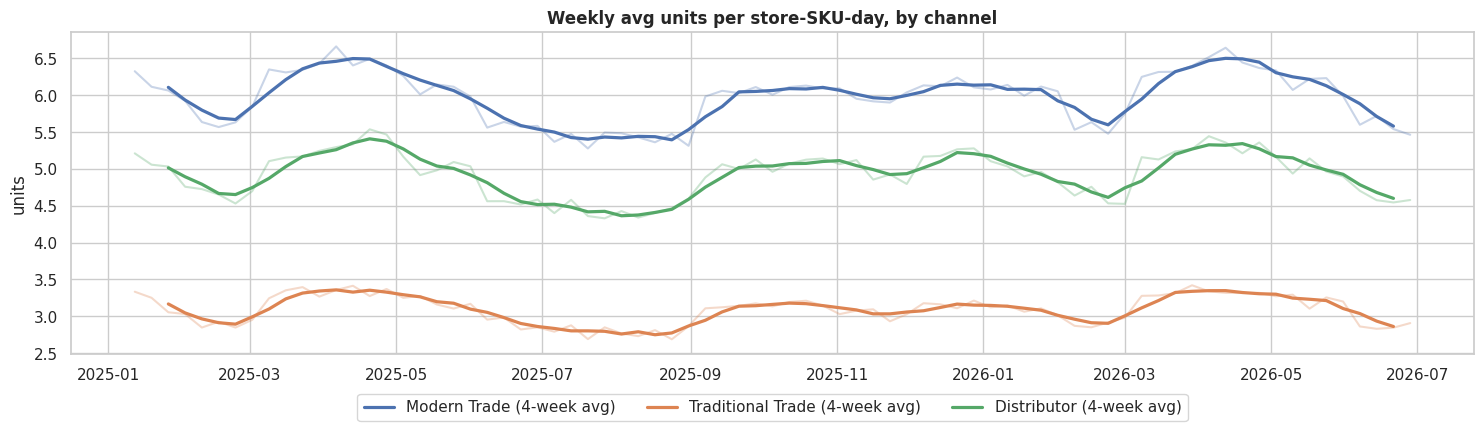

In [28]:
wk = sof.groupby([pd.Grouper(key='date', freq='W'), 'channel']).units_sold_daily.mean().unstack()[CH_ORDER].iloc[1:-1]
fig, ax = plt.subplots(figsize=(15, 4.5))
for ch in CH_ORDER:
    ax.plot(wk.index, wk[ch], color=CH_COL[ch], alpha=0.3)
    ax.plot(wk.index, wk[ch].rolling(4, center=True).mean(), color=CH_COL[ch], lw=2.3, label=f'{ch} (4-week avg)')
ax.set_title('Weekly avg units per store-SKU-day, by channel'); ax.set_ylabel('units')
ax.legend(ncol=3, loc='upper center', bbox_to_anchor=(0.5, -0.1))
plt.tight_layout(); plt.show()

**Notes:** No long-term growth or decline, just repeating ups and downs. All three channels move together, which already hints at seasonality that's the same across channels.

### 6.2 Monthly seasonality by category

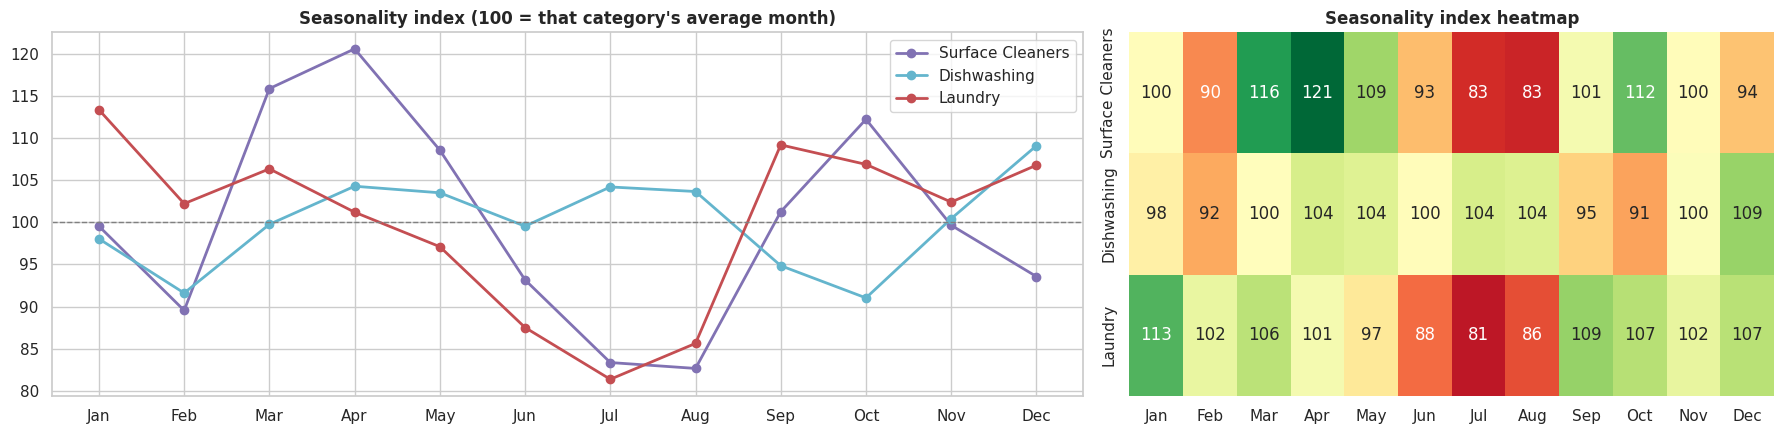

In [29]:
cat_month = sof.groupby([sof.date.dt.month, 'category']).units_sold_daily.mean().unstack()[CAT_ORDER]
cat_index = cat_month / cat_month.mean() * 100
fig, axes = plt.subplots(1, 2, figsize=(18, 4.5), gridspec_kw={'width_ratios': [1.6, 1]})
for c in CAT_ORDER:
    axes[0].plot(range(1, 13), cat_index[c], marker='o', color=CAT_COL[c], label=c, lw=2)
axes[0].axhline(100, color='grey', ls='--', lw=1)
axes[0].set_xticks(range(1, 13)); axes[0].set_xticklabels(MONTHS)
axes[0].set_title("Seasonality index (100 = that category's average month)"); axes[0].legend()
heatmap(cat_index.T.set_axis(MONTHS, axis=1), annot=True, fmt='.0f', cmap='RdYlGn', center=100, ax=axes[1], cbar=False)
axes[1].set_title('Seasonality index heatmap'); axes[1].set_xlabel(''); axes[1].set_ylabel('')
plt.tight_layout(); plt.show()

**Notes:** This is real, category-specific seasonality:
1. **Surface Cleaners** peak in **March–April** (spring cleaning!) at ~120, again in October, and drop hard in July–August (~83).
2. **Laundry** is lowest in **summer** (June–August) and highest in January and September.
3. **Dishwashing** is the steadiest, with its peak in **December** (holiday cooking and hosting, we guess).
4. February is a weak month for Surface Cleaners and Dishwashing.

(Small caveat: Jan–Jun appear twice in the data but Jul–Dec only once, so the second half of the year is based on less data.)

### 6.3 Seasonal decomposition (daily)
We split the daily average into a trend, a weekly pattern and leftover noise.

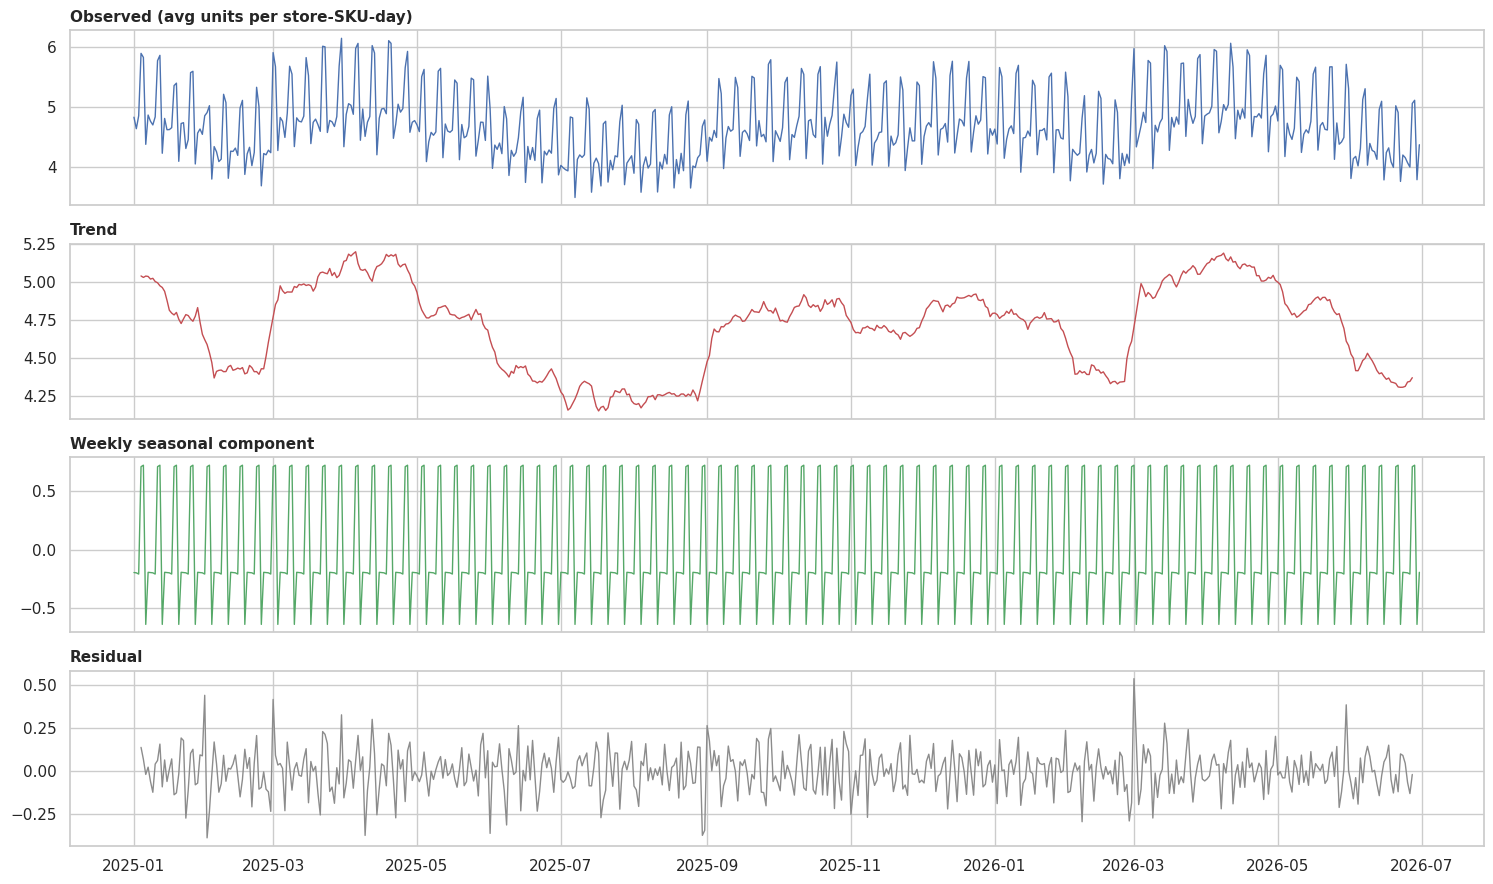

In [30]:
daily = sof.groupby('date').units_sold_daily.mean().asfreq('D')
dec = seasonal_decompose(daily, model='additive', period=7)
fig, axes = plt.subplots(4, 1, figsize=(15, 9), sharex=True)
for ax, series, title, color in zip(axes, [dec.observed, dec.trend, dec.seasonal, dec.resid],
                                    ['Observed (avg units per store-SKU-day)', 'Trend', 'Weekly seasonal component', 'Residual'],
                                    ['#4C72B0', '#C44E52', '#55A868', '#8C8C8C']):
    ax.plot(series.index, series.values, color=color, lw=1)
    ax.set_title(title, fontsize=11, loc='left')
plt.tight_layout(); plt.show()

**Notes:** The trend line shows the same yearly wave as 6.2 (spring and autumn peaks, summer dip), and it looks almost identical in 2025 and 2026. The weekly component is a clean repeating pattern (next chart), and the residual is small with no obvious structure left.

One thing we noticed: the trend moves in **steps** rather than smooth curves. When we checked the daily numbers, the jumps happen exactly on the 1st of the month (for example, from ~4.4 on 28 Feb to ~5.1 on 1 Mar 2025, after removing the weekday effect). So the simulation seems to use one seasonal multiplier per month. For forecasting, that means a simple "month factor" should capture the seasonality well.

### 6.4 Day-of-week effect

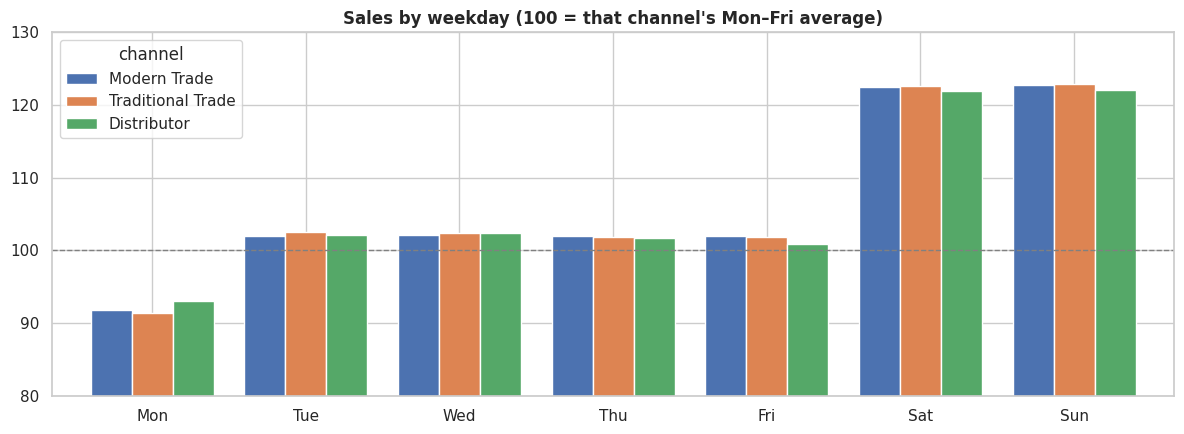

Weekend vs weekday: +23%


In [31]:
dow_ch = sof.groupby(['channel', sof.date.dt.dayofweek]).units_sold_daily.mean().unstack(0)[CH_ORDER]
dow_idx = dow_ch / dow_ch.iloc[:5].mean() * 100
fig, ax = plt.subplots(figsize=(12, 4.5))
dow_idx.set_axis(DAYS).plot.bar(ax=ax, color=[CH_COL[c] for c in CH_ORDER], rot=0, width=0.8)
ax.axhline(100, color='grey', ls='--', lw=1); ax.set_ylim(80, 130)
ax.set_title("Sales by weekday (100 = that channel's Mon–Fri average)"); ax.set_xlabel('')
plt.tight_layout(); plt.show()
dow_all = sof.groupby(sof.date.dt.dayofweek).units_sold_daily.mean()
print(f"Weekend vs weekday: {dow_all[[5, 6]].mean() / dow_all[:5].mean() - 1:+.0%}")

**Notes:** Weekends sell about **23% more** than weekdays, in every channel, and Monday is the slowest day. For the perfect order suggestion, a delivery *before* the weekend matters more than one after.

### 6.5 Year-over-year (Jan–Jun 2025 vs 2026)

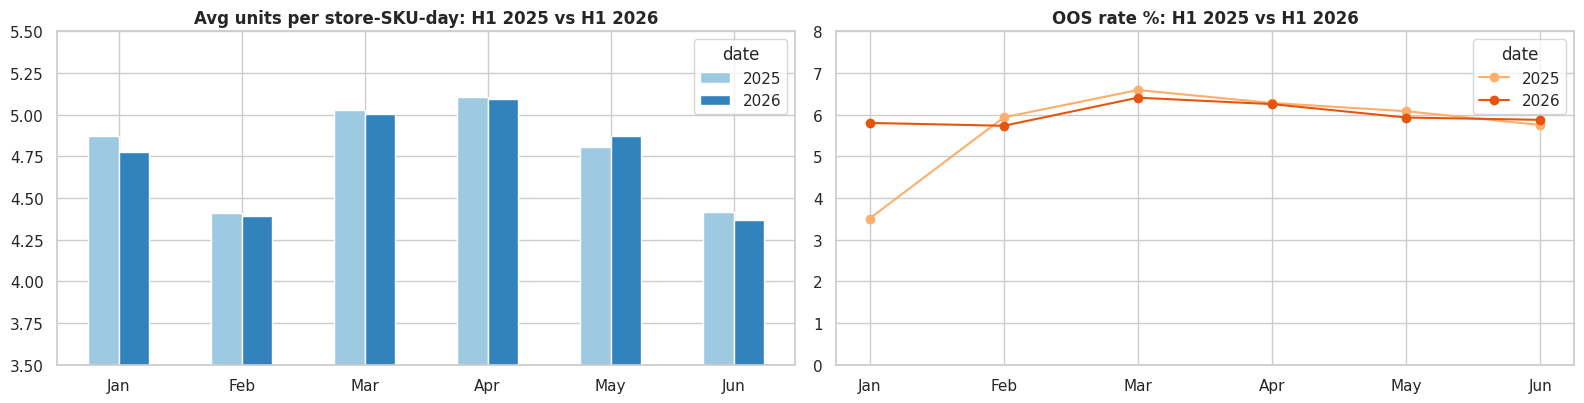

In [32]:
h1 = sof[sof.date.dt.month <= 6]
yoy = h1.groupby([h1.date.dt.month, h1.date.dt.year]).agg(units=('units_sold_daily', 'mean'), oos=('is_out_of_stock', 'mean')).unstack()
fig, axes = plt.subplots(1, 2, figsize=(16, 4.2))
yoy['units'].set_axis(MONTHS[:6]).plot.bar(ax=axes[0], rot=0, color=['#9ecae1', '#3182bd'])
axes[0].set_title('Avg units per store-SKU-day: H1 2025 vs H1 2026'); axes[0].set_xlabel(''); axes[0].set_ylim(3.5, 5.5)
(yoy['oos'] * 100).set_axis(MONTHS[:6]).plot(ax=axes[1], marker='o', color=['#fdae6b', '#e6550d'])
axes[1].set_title('OOS rate %: H1 2025 vs H1 2026'); axes[1].set_ylim(0, 8); axes[1].set_xlabel('')
plt.tight_layout(); plt.show()

**Notes:** The two years are almost identical month by month, so there's no growth built into the data. The one exception is **January 2025, where OOS is only ~3.5%** (vs ~5.8% in January 2026). We think the simulation starts everyone with full shelves, so January 2025 is a warm-up month, and we drop it when training the model.

## 7. The brief's KPIs (baseline values)
Module 1 asks for five KPIs. Before building the dashboard, we wanted to know their current values and how they behave.

### 7.1 Definitions we used
The brief doesn't define every KPI precisely, so these are *our* working definitions (to confirm with Dr. Masse):

| KPI | Our definition | Source |
|---|---|---|
| OOS rate % | share of store-SKU-days with end-of-day stock = 0 | sell-out |
| MSL compliance % | share of store-days where **all** MSL SKUs are in stock | sell-out + products |
| Sell-in vs sell-out gap % | (sell-in units ÷ sell-out units) − 1 | sell-in + sell-out |
| Shelf share % | average `shelf_share_pct` across audited SKUs | audits |
| Planogram compliance % | share of audited SKUs that follow the planogram | audits |

### 7.2 KPI scorecard

In [33]:
msl_ids = set(products.loc[products.is_msl, 'sku_id'])
msl_sd = (sof[sof.sku_id.isin(msl_ids)].groupby(['store_id', 'date', 'channel', 'region']).is_out_of_stock.sum()
            .rename('msl_oos').reset_index())
msl_sd['msl_compliant'] = msl_sd.msl_oos == 0

def kpi_table(by):
    return pd.DataFrame({
        'OOS rate %': sof.groupby(by).is_out_of_stock.mean() * 100,
        'MSL compliance %': msl_sd.groupby(by).msl_compliant.mean() * 100,
        'Sell-in vs sell-out gap %': (si.groupby(by).units_sold.sum() / sof.groupby(by).units_sold_daily.sum() - 1) * 100,
        'Shelf share %': au.groupby(by).shelf_share_pct.mean(),
        'Planogram compliance %': au.groupby(by).planogram_compliance.mean() * 100})

overall = pd.DataFrame({
    'OOS rate %': [sof.is_out_of_stock.mean() * 100], 'MSL compliance %': [msl_sd.msl_compliant.mean() * 100],
    'Sell-in vs sell-out gap %': [(si.units_sold.sum() / sof.units_sold_daily.sum() - 1) * 100],
    'Shelf share %': [au.shelf_share_pct.mean()], 'Planogram compliance %': [au.planogram_compliance.mean() * 100]}, index=['All stores'])
scorecard = pd.concat([kpi_table('channel').reindex(CH_ORDER), overall])
scorecard.round(1)

,OOS rate %,MSL compliance %,Sell-in vs sell-out gap %,Shelf share %,Planogram compliance %
Modern Trade,5.8,41.7,10.9,38.8,88.8
Traditional Trade,6.4,37.6,-45.2,30.5,75.5
Distributor,5.7,41.4,10.5,33.8,80.7
All stores,6.0,40.1,-3.2,35.2,83.0


**Notes**
1. **OOS rate** is ~6% everywhere; Traditional Trade is only slightly worse.
2. **MSL compliance** is only ~40% under our strict definition. With 15 MSL SKUs that are each ~94% available, the chance that *all 15* are in stock on the same day is pretty low.
3. **Sell-in vs sell-out gap** is the odd one: about **+11%** for Modern Trade and Distributors but **−45%** for Traditional Trade (more in 8.3).
4. **Shelf share** and **planogram** are clearly worst in Traditional Trade.

### 7.3 KPI trends over time

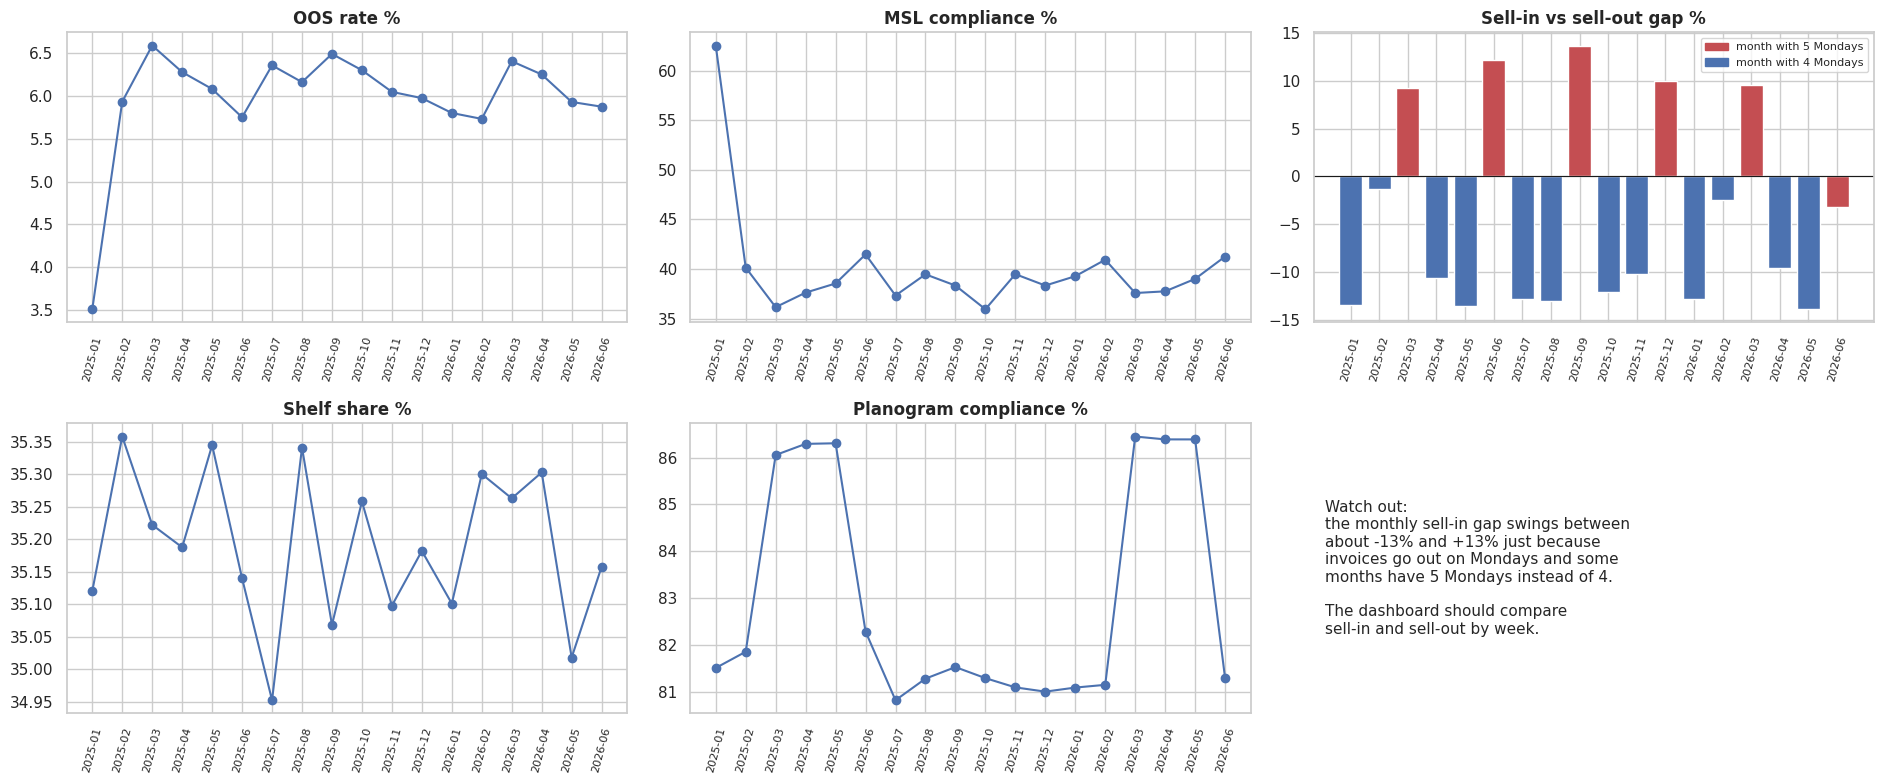

In [34]:
month = lambda d: d.date.dt.to_period('M')
monthly = pd.DataFrame({
    'OOS rate %': sof.groupby(month(sof)).is_out_of_stock.mean() * 100,
    'MSL compliance %': msl_sd.groupby(month(msl_sd)).msl_compliant.mean() * 100,
    'Sell-in vs sell-out gap %': (si.groupby(month(si)).units_sold.sum() / sof.groupby(month(sof)).units_sold_daily.sum() - 1) * 100,
    'Shelf share %': au.groupby(month(au)).shelf_share_pct.mean(),
    'Planogram compliance %': au.groupby(month(au)).planogram_compliance.mean() * 100}).dropna()
mondays = pd.Series(pd.date_range('2025-01-01', '2026-06-30', freq='W-MON')).dt.to_period('M').value_counts()

fig, axes = plt.subplots(2, 3, figsize=(19, 8))
for ax, col in zip(axes.flat, monthly.columns):
    x = monthly.index.astype(str)
    if col.startswith('Sell-in'):
        colors = ['#C44E52' if mondays.get(p, 0) == 5 else '#4C72B0' for p in monthly.index]
        ax.bar(x, monthly[col], color=colors); ax.axhline(0, color='k', lw=0.8)
        ax.legend(handles=[Patch(color='#C44E52', label='month with 5 Mondays'), Patch(color='#4C72B0', label='month with 4 Mondays')], fontsize=8)
    else:
        ax.plot(x, monthly[col], marker='o', color='#4C72B0')
    ax.set_title(col); ax.tick_params(axis='x', rotation=75, labelsize=8)
axes[1, 2].axis('off')
axes[1, 2].text(0.02, 0.5, 'Watch out:\nthe monthly sell-in gap swings between\nabout -13% and +13% just because\ninvoices go out on Mondays and some\nmonths have 5 Mondays instead of 4.\n\nThe dashboard should compare\nsell-in and sell-out by week.',
                fontsize=11, va='center')
plt.tight_layout(); plt.show()

**Notes**
1. **OOS rate** is flat around 6%, apart from the January 2025 warm-up.
2. **MSL compliance** is also flat (~36–41%), with the same January 2025 spike.
3. **Shelf share** barely moves at all (~35% every month).
4. **Planogram compliance** has a pattern we didn't expect: it jumps to **~86% in March–May** in both years, and sits around ~81% the rest of the time. Maybe a spring shelf reset built into the simulation?
5. **The monthly sell-in gap is misleading.** It swings between about −13% and +13%, and the red bars show why: months with 5 Mondays get 5 invoices. That's a calendar effect, not a business signal. (June 2026 is the one exception because its last invoice only covers a partial week, see 8.3.) Good thing we caught this before building the dashboard.

### 7.4 KPIs by region and channel

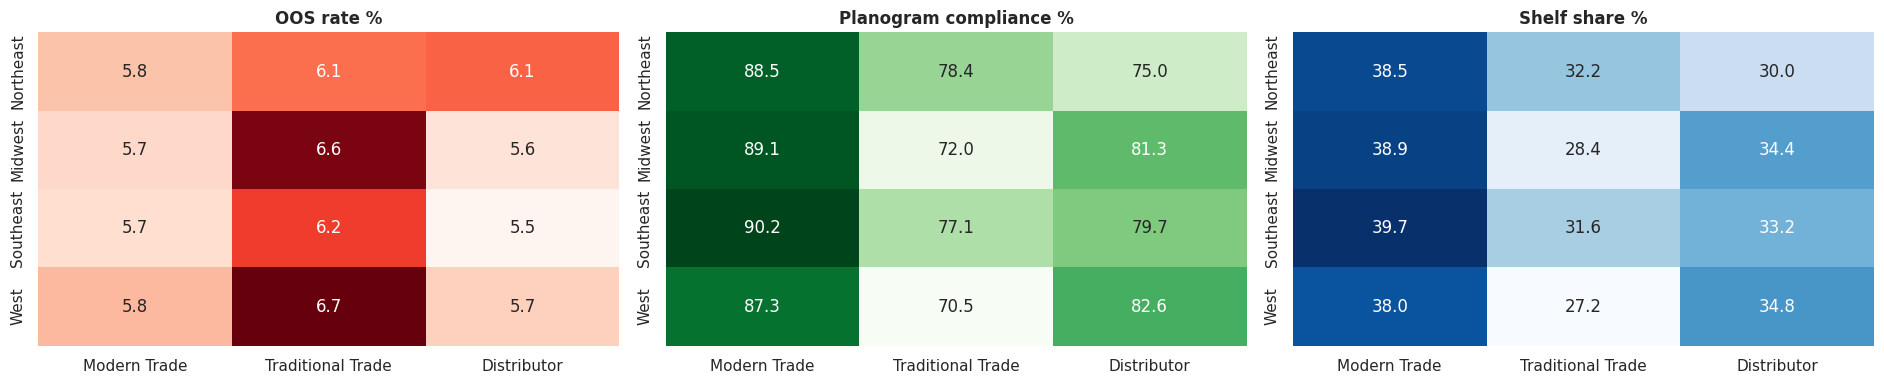

In [35]:
fig, axes = plt.subplots(1, 3, figsize=(19, 4))
for ax, (title, frame, col, mult, cmap) in zip(axes, [
        ('OOS rate %', sof, 'is_out_of_stock', 100, 'Reds'),
        ('Planogram compliance %', au, 'planogram_compliance', 100, 'Greens'),
        ('Shelf share %', au, 'shelf_share_pct', 1, 'Blues')]):
    hm = frame.pivot_table(index='region', columns='channel', values=col, aggfunc='mean').reindex(REGION_ORDER)[CH_ORDER] * mult
    heatmap(hm, annot=True, fmt='.1f', cmap=cmap, ax=ax, cbar=False)
    ax.set_title(title); ax.set_xlabel(''); ax.set_ylabel('')
plt.tight_layout(); plt.show()

**Notes:** Region makes very little difference for OOS. Execution differences are mostly about channel: Modern Trade planogram is ~87–90% in every region, while Traditional Trade is ~70–78%. The weakest cells are Traditional Trade in the West and Midwest.

### 7.5 The "62%" in the brief
The brief says only 62% of stores comply with the planogram and MSL. We tried several reasonable definitions to see if we could reproduce it:

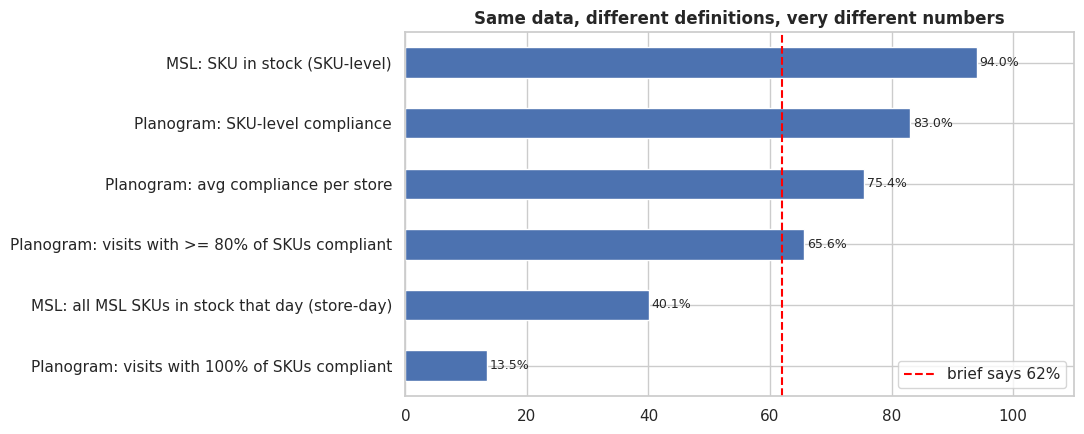

In [36]:
msl_rows = sof[sof.sku_id.isin(msl_ids)]
visit_plano = audits.groupby(['store_id', 'date']).planogram_compliance.mean()
defs = pd.Series({
    'MSL: SKU in stock (SKU-level)': 1 - msl_rows.is_out_of_stock.mean(),
    'MSL: all MSL SKUs in stock that day (store-day)': msl_sd.msl_compliant.mean(),
    'Planogram: SKU-level compliance': audits.planogram_compliance.mean(),
    'Planogram: avg compliance per store': audits.groupby('store_id').planogram_compliance.mean().mean(),
    'Planogram: visits with >= 80% of SKUs compliant': (visit_plano >= 0.8).mean(),
    'Planogram: visits with 100% of SKUs compliant': (visit_plano == 1).mean()}) * 100
fig, ax = plt.subplots(figsize=(11, 4.5))
defs.sort_values().plot.barh(ax=ax, color='#4C72B0')
ax.axvline(62, color='red', ls='--', label='brief says 62%')
label_bars(ax, '{:.1f}%'); ax.legend(loc='lower right'); ax.set_xlim(0, 110)
ax.set_title('Same data, different definitions, very different numbers')
plt.tight_layout(); plt.show()

**Notes:** Depending on the definition we get anything from ~13% to ~94%, and none of them is exactly 62%. We need Dr. Masse to confirm the definitions, otherwise our dashboard might show numbers that "look wrong" to Globant.

## 8. Deep dives

### 8.1 Out-of-stocks
OOS is problem number one in the brief, so we looked at it from every angle.

Overall OOS rate: 5.97% of store-SKU-days


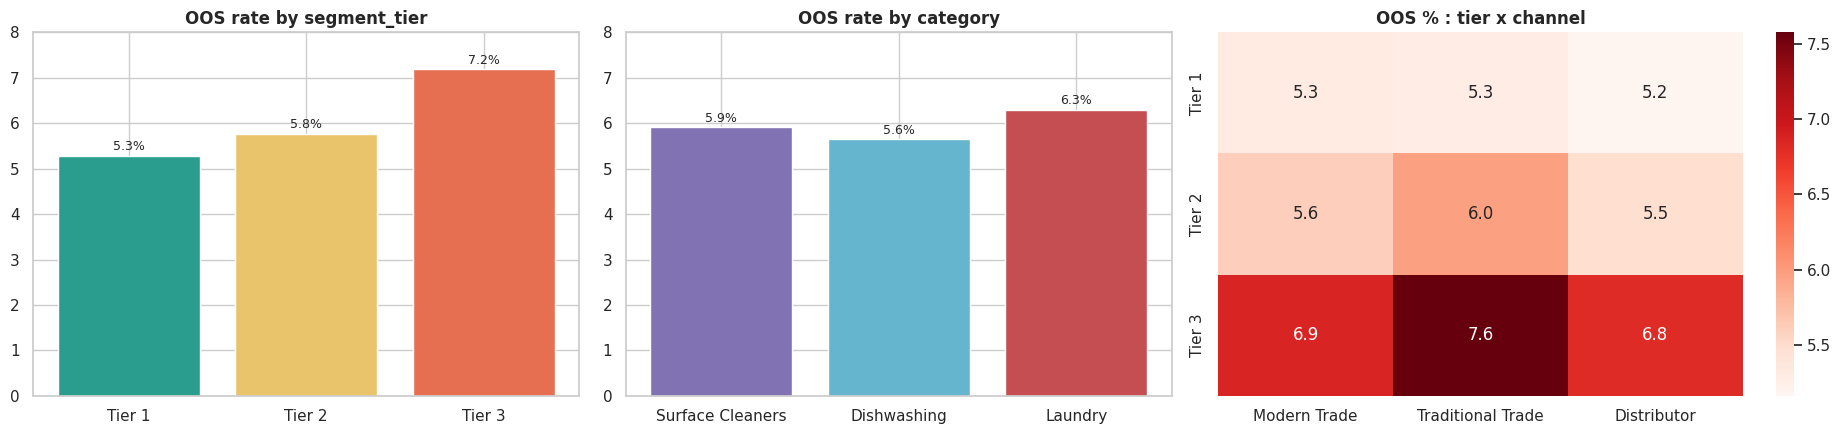

In [37]:
print(f"Overall OOS rate: {sof.is_out_of_stock.mean():.2%} of store-SKU-days")
fig, axes = plt.subplots(1, 3, figsize=(19, 4.5), gridspec_kw={'width_ratios': [1, 1, 1.2]})
for ax, col, order, pal in [(axes[0], 'segment_tier', TIER_ORDER, TIER_COL), (axes[1], 'category', CAT_ORDER, CAT_COL)]:
    r = sof.groupby(col).is_out_of_stock.mean().reindex(order) * 100
    ax.bar(r.index, r.values, color=[pal[x] for x in r.index]); label_bars(ax, '{:.1f}%')
    ax.set_title(f'OOS rate by {col}'); ax.set_ylim(0, 8)
hm = sof.pivot_table(index='segment_tier', columns='channel', values='is_out_of_stock', aggfunc='mean').reindex(TIER_ORDER)[CH_ORDER] * 100
heatmap(hm, annot=True, fmt='.1f', cmap='Reds', ax=axes[2]); axes[2].set_title('OOS % : tier x channel'); axes[2].set_xlabel(''); axes[2].set_ylabel('')
plt.tight_layout(); plt.show()

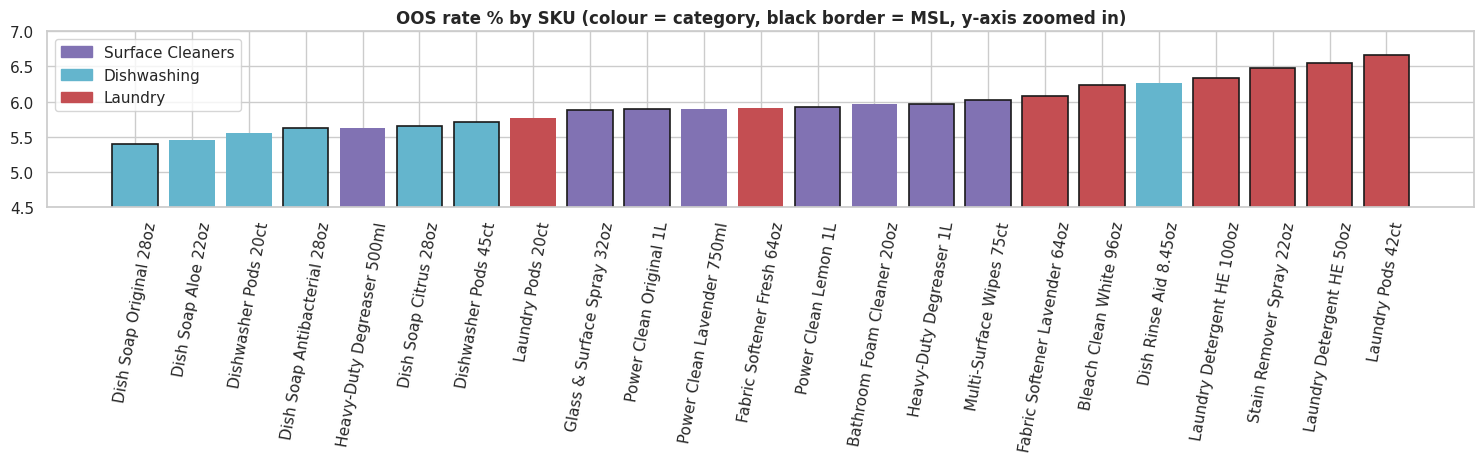

In [38]:
by_sku = (sof.groupby(['sku_id', 'product_name', 'category', 'is_msl']).is_out_of_stock.mean() * 100).reset_index().sort_values('is_out_of_stock')
fig, ax = plt.subplots(figsize=(15, 4.8))
ax.bar(by_sku.product_name.str.replace('Marvel ', ''), by_sku.is_out_of_stock, color=[CAT_COL[c] for c in by_sku.category],
       edgecolor=['k' if m else 'none' for m in by_sku.is_msl], linewidth=1.2)
ax.set_ylim(4.5, 7); ax.tick_params(axis='x', rotation=80)
ax.set_title('OOS rate % by SKU (colour = category, black border = MSL, y-axis zoomed in)')
ax.legend(handles=[Patch(color=CAT_COL[c], label=c) for c in CAT_ORDER], loc='upper left')
plt.tight_layout(); plt.show()

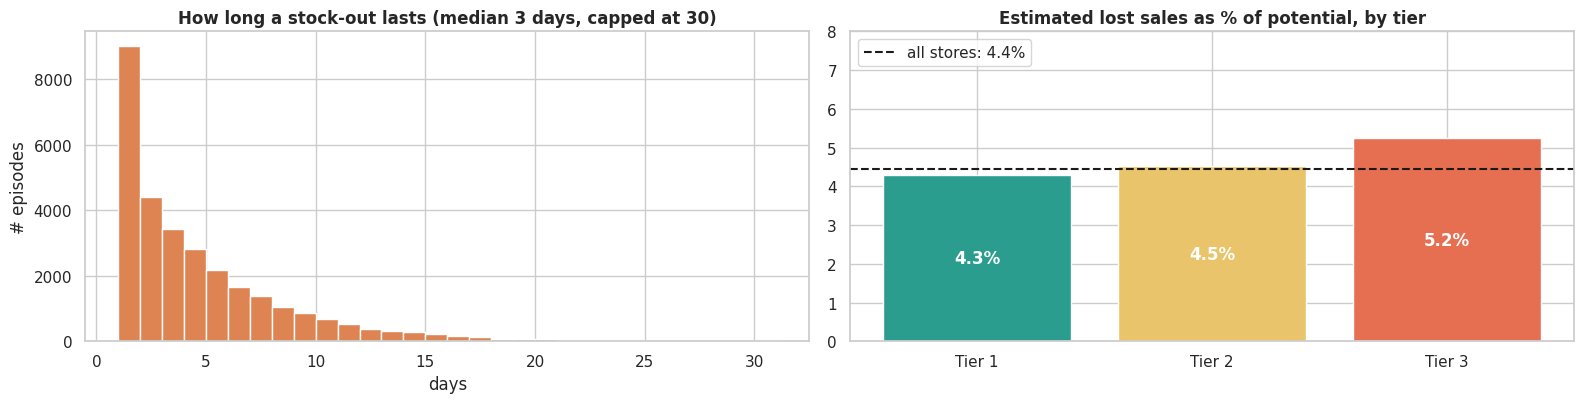

29,892 OOS episodes | 90% last 10 days or less | estimated lost sales $1,741,856


In [39]:
is_oos = so.is_out_of_stock
new_episode = is_oos & ~so.groupby(['store_id', 'sku_id']).is_out_of_stock.shift(fill_value=False)
so['episode'] = new_episode.groupby([so.store_id, so.sku_id]).cumsum()
ep = so[is_oos].groupby(['store_id', 'sku_id', 'episode']).date.agg(['min', 'max'])
ep_len = (ep['max'] - ep['min']).dt.days + 1

# rough lost sales: on OOS days, assume the store would have sold its normal in-stock daily average
normal_daily = so[~so.is_out_of_stock].groupby(['store_id', 'sku_id']).units_sold_daily.mean().rename('normal_daily')
ls = sof[['store_id', 'sku_id', 'is_out_of_stock', 'units_sold_daily', 'list_price', 'segment_tier']].merge(normal_daily, on=['store_id', 'sku_id'])
ls['lost_value'] = np.where(ls.is_out_of_stock, (ls.normal_daily - ls.units_sold_daily).clip(lower=0), 0) * ls.list_price
ls['actual_value'] = ls.units_sold_daily * ls.list_price
lost_tier = ls.groupby('segment_tier')[['lost_value', 'actual_value']].sum().reindex(TIER_ORDER)
lost_pct = lost_tier.lost_value / (lost_tier.lost_value + lost_tier.actual_value) * 100
total_lost = ls.lost_value.sum() / (ls.lost_value.sum() + ls.actual_value.sum())

fig, axes = plt.subplots(1, 2, figsize=(16, 4.2))
axes[0].hist(ep_len.clip(upper=30), bins=range(1, 32), color='#DD8452')
axes[0].set_title(f'How long a stock-out lasts (median {ep_len.median():.0f} days, capped at 30)'); axes[0].set_xlabel('days'); axes[0].set_ylabel('# episodes')
bars = axes[1].bar(lost_pct.index, lost_pct.values, color=[TIER_COL[t] for t in lost_pct.index])
axes[1].bar_label(bars, labels=[f'{v:.1f}%' for v in lost_pct.values], label_type='center', color='white', fontweight='bold')
axes[1].axhline(total_lost * 100, color='k', ls='--', label=f'all stores: {total_lost:.1%}')
axes[1].set_title('Estimated lost sales as % of potential, by tier'); axes[1].legend(loc='upper left'); axes[1].set_ylim(0, 8)
plt.tight_layout(); plt.show()
print(f"{len(ep_len):,} OOS episodes | 90% last {ep_len.quantile(.9):.0f} days or less | estimated lost sales ${ls.lost_value.sum():,.0f}")
del ls; _ = gc.collect()

**What we found**
1. About **6%** of store-SKU-days are out of stock, and it's surprisingly **flat** across channels, regions and categories.
2. **Tier is the real driver**: Tier 3 stores are OOS ~7.2% of the time vs ~5.3% for Tier 1. Traditional Trade Tier 3 is the worst cell.
3. By SKU the range is narrow (~5.4% to ~6.7%), with laundry products at the top.
4. A stock-out usually lasts **about 3 days**, and 90% are over within 10 days.
5. For lost sales we used a simple method: on OOS days, assume the store would have sold its normal in-stock daily average. That gives **~4–5% of potential sales**, clearly below the brief's 8–12%. Our method is basic, so it's worth asking Dr. Masse where the 8–12% comes from.

### 8.2 Stock and replenishment

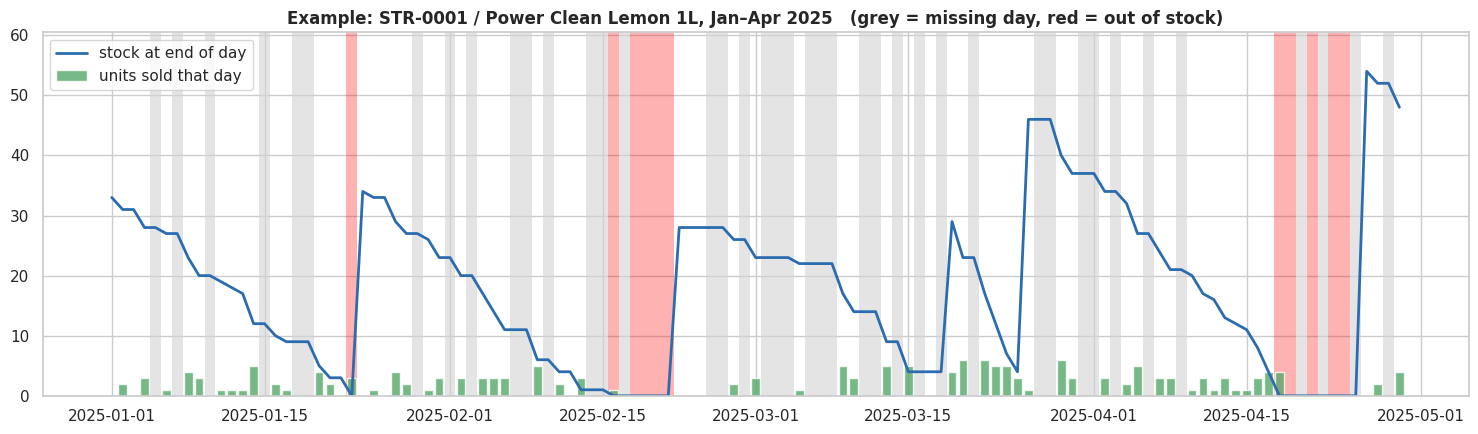

In [40]:
ex = so[(so.store_id == 'STR-0001') & (so.sku_id == 'SKU-1001') & (so.date < '2025-05-01')]
full = ex.set_index('date').reindex(pd.date_range(ex.date.min(), ex.date.max()))
half = pd.Timedelta(hours=12)
fig, ax = plt.subplots(figsize=(15, 4.5))
for d in full.index[full.inventory_level.isna()]:
    ax.axvspan(d - half, d + half, color='lightgrey', alpha=0.6, lw=0)
for d in ex.date[ex.is_out_of_stock]:
    ax.axvspan(d - half, d + half, color='red', alpha=0.3, lw=0)
ax.plot(full.index, full.inventory_level.ffill(), color='#2b6cb0', lw=2, label='stock at end of day')
ax.bar(ex.date, ex.units_sold_daily, color='#55A868', alpha=0.8, label='units sold that day')
ax.set_title('Example: STR-0001 / Power Clean Lemon 1L, Jan–Apr 2025   (grey = missing day, red = out of stock)')
ax.set_ylim(0, full.inventory_level.max() * 1.12); ax.legend(loc='upper left')
plt.tight_layout(); plt.show()

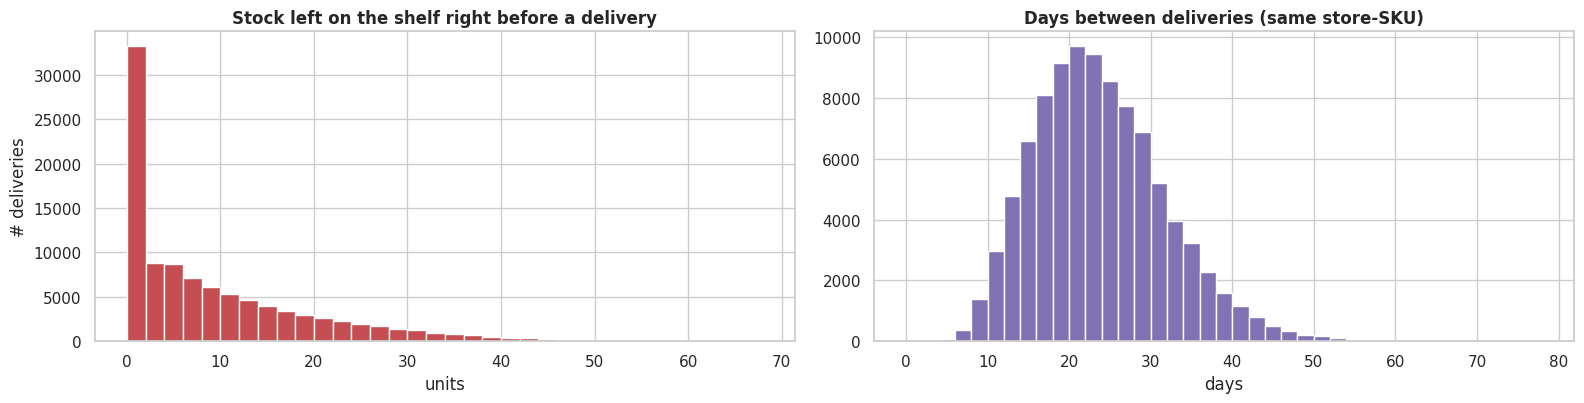

Deliveries that arrived only after the shelf was already empty: 29.7%
Days between deliveries: median 22 (10th pct 13, 90th pct 34)


In [41]:
deliv = so[so.delivered > 0].copy()
deliv['days_between'] = deliv.groupby(['store_id', 'sku_id']).date.diff().dt.days
fig, axes = plt.subplots(1, 2, figsize=(16, 4.2))
axes[0].hist(deliv.prev_inv, bins=range(0, 70, 2), color='#C44E52')
axes[0].set_title('Stock left on the shelf right before a delivery'); axes[0].set_xlabel('units'); axes[0].set_ylabel('# deliveries')
axes[1].hist(deliv.days_between.dropna(), bins=range(0, 80, 2), color='#8172B3')
axes[1].set_title('Days between deliveries (same store-SKU)'); axes[1].set_xlabel('days')
plt.tight_layout(); plt.show()
print(f"Deliveries that arrived only after the shelf was already empty: {(deliv.prev_inv == 0).mean():.1%}")
print(f"Days between deliveries: median {deliv.days_between.median():.0f} (10th pct {deliv.days_between.quantile(.1):.0f}, 90th pct {deliv.days_between.quantile(.9):.0f})")

**What we found**
1. The example shows the typical cycle: stock runs down, sometimes hits zero (red), then a delivery refills it.
2. **Deliveries don't follow a neat schedule.** They arrive with anywhere from 0 to ~60 units still on the shelf, and **~30% arrive only after the shelf is already empty**. The time between deliveries is also all over the place (median 22 days, most between 13 and 34).

This turned out to be the key to section 9. Even if we know stock is low, we can't know whether the delivery arrives before the shelf empties, so there's a limit to how precisely anyone can predict OOS.

### 8.3 Sell-in vs sell-out

Sell-in weekdays: {'Monday': 277969} | distinct invoice dates: 79


,mean,min,50%,max
channel,,,,
Modern Trade,78.9,77.0,79.0,79.0
Traditional Trade,39.5,24.0,39.0,54.0
Distributor,78.8,78.0,79.0,79.0


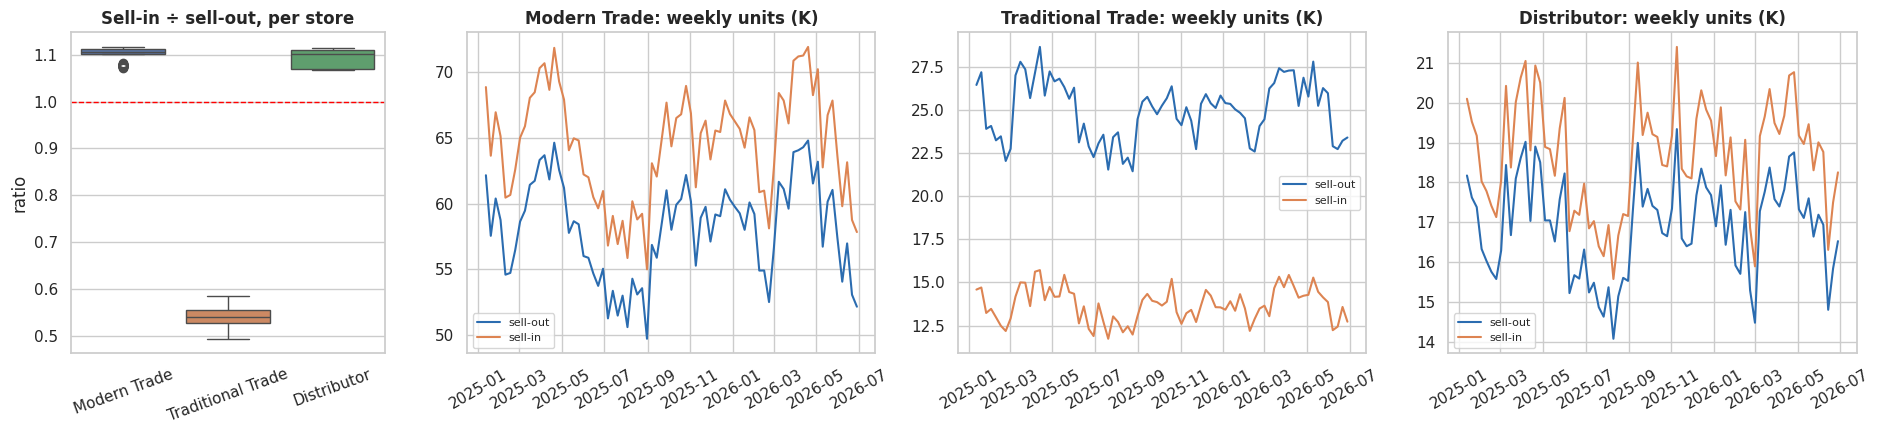

In [42]:
print('Sell-in weekdays:', sell_in.date.dt.day_name().value_counts().to_dict(), '| distinct invoice dates:', sell_in.date.nunique())
weeks = si.groupby(['channel', 'store_id', 'sku_id']).date.nunique().rename('weeks_invoiced').reset_index()
display(weeks.groupby('channel').weeks_invoiced.describe()[['mean', 'min', '50%', 'max']].reindex(CH_ORDER).round(1))

store_ratio = ((si.groupby('store_id').units_sold.sum() / sof.groupby('store_id').units_sold_daily.sum())
               .rename('ratio').reset_index().merge(stores[['store_id', 'channel']], on='store_id'))
wk_in = si.groupby(['channel', pd.Grouper(key='date', freq='W-SUN')]).units_sold.sum()
wk_out = sof.groupby(['channel', pd.Grouper(key='date', freq='W-SUN')]).units_sold_daily.sum()

fig = plt.figure(figsize=(19, 4.5))
gs = fig.add_gridspec(1, 4, width_ratios=[1, 1.3, 1.3, 1.3])
ax0 = fig.add_subplot(gs[0])
sns.boxplot(data=store_ratio, x='channel', y='ratio', order=CH_ORDER, hue='channel', palette=CH_COL, legend=False, ax=ax0)
ax0.axhline(1, color='red', ls='--', lw=1); ax0.set_title('Sell-in ÷ sell-out, per store'); ax0.set_xlabel(''); ax0.tick_params(axis='x', rotation=20)
for i, ch in enumerate(CH_ORDER):
    ax = fig.add_subplot(gs[i + 1])
    a, b = wk_in[ch].iloc[1:-1], wk_out[ch].iloc[1:-1]
    ax.plot(b.index, b.values / 1e3, label='sell-out', color='#2b6cb0'); ax.plot(a.index, a.values / 1e3, label='sell-in', color='#DD8452')
    ax.set_title(f'{ch}: weekly units (K)'); ax.legend(fontsize=8); ax.tick_params(axis='x', rotation=30)
plt.tight_layout(); plt.show()

In [43]:
# do the invoices match the deliveries we can see in the stock data?
seen = so[so.delivered > 0].merge(stores[['store_id', 'channel']], on='store_id').groupby('channel').delivered.sum()
cmp_ = pd.concat([si.groupby('channel').units_sold.sum().rename('invoiced_units'), seen.rename('deliveries_seen_in_stock')], axis=1).reindex(CH_ORDER)
cmp_['deliveries_vs_invoices'] = (cmp_.deliveries_seen_in_stock / cmp_.invoiced_units).round(2)
cmp_

,invoiced_units,deliveries_seen_in_stock,deliveries_vs_invoices
channel,,,
Modern Trade,5029653,4446529.0,0.88
Traditional Trade,1069055,1908382.0,1.79
Distributor,1458519,1292982.0,0.89


**What we found**
1. All invoices are on **Mondays**. Modern Trade and Distributors are invoiced every week (79 weeks), **Traditional Trade only about every second week** (39 weeks on average).
2. Modern Trade and Distributors are invoiced ~**10% more** than they sell; Traditional Trade only about **half**. The spread between stores is tiny, so the gap is basically **one fixed number per channel**, not a store-level story.
3. The deliveries we can see in the stock data don't match the invoices either: ~12% fewer units than invoiced for Modern Trade and Distributors, and ~80% *more* for Traditional Trade.
4. Clue about how sell-in was made: the first invoice (30 Dec 2024) is about 5/7 of a normal week and the last one (29 Jun 2026) only about 2/7. Those are exactly the share of days of those weeks that fall inside the sell-out data. So it looks like each invoice was generated from that week's sell-out (× ~1.1 for Modern Trade and Distributors), separately from the stock simulation.

### 8.4 Prices, discounts and elasticity
Scenario B of the simulator asks for price elasticity "from historical sell-out data", so we checked whether the data can support that.

Price or revenue columns in sell-out: none


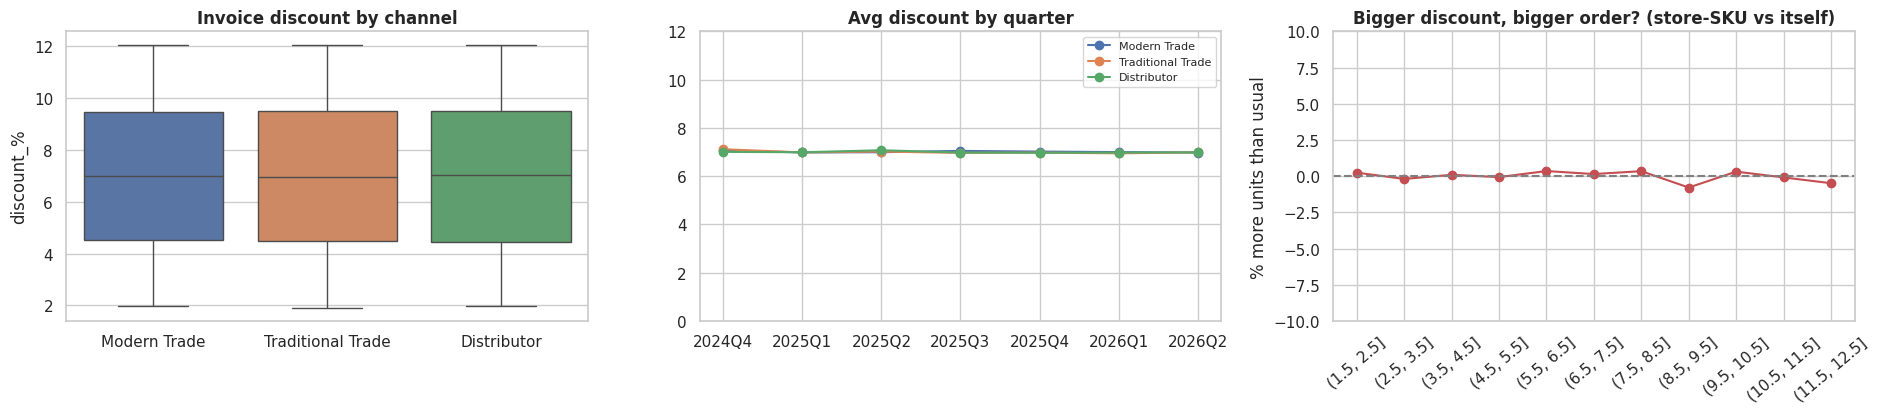

Correlation, discount vs order size (within store-SKU): -0.0011
Marvel margin on invoice price: mean 49.1%, range 44.4% to 53.4%


In [44]:
print('Price or revenue columns in sell-out:', [c for c in sell_out.columns if 'price' in c or 'sales' in c.replace('units_sold_daily', '')] or 'none')
si['log_units'] = np.log(si.units_sold)
si['units_vs_usual'] = si.log_units - si.groupby(k).log_units.transform('mean')
si['disc_vs_usual'] = si['discount_%'] - si.groupby(k)['discount_%'].transform('mean')
si['disc_bin'] = pd.cut(si['discount_%'], bins=np.arange(1.5, 13, 1))
b = si.groupby('disc_bin', observed=True).units_vs_usual.mean()
q = si.groupby([si.date.dt.to_period('Q').astype(str), 'channel'])['discount_%'].mean().unstack()[CH_ORDER]

fig, axes = plt.subplots(1, 3, figsize=(19, 4.3))
sns.boxplot(data=si.sample(100_000, random_state=0), x='channel', y='discount_%', order=CH_ORDER, hue='channel', palette=CH_COL, legend=False, ax=axes[0])
axes[0].set_title('Invoice discount by channel'); axes[0].set_xlabel('')
for ch in CH_ORDER:
    axes[1].plot(q.index, q[ch], marker='o', color=CH_COL[ch], label=ch)
axes[1].set_ylim(0, 12); axes[1].set_title('Avg discount by quarter'); axes[1].legend(fontsize=8)
axes[2].plot(b.index.astype(str), (np.exp(b.values) - 1) * 100, marker='o', color='#C44E52')
axes[2].axhline(0, color='grey', ls='--'); axes[2].set_ylim(-10, 10); axes[2].tick_params(axis='x', rotation=40)
axes[2].set_title('Bigger discount, bigger order? (store-SKU vs itself)'); axes[2].set_ylabel('% more units than usual')
plt.tight_layout(); plt.show()
margin = (si.unit_price - si.unit_cost) / si.unit_price
print('Correlation, discount vs order size (within store-SKU):', round(np.corrcoef(si.disc_vs_usual, si.units_vs_usual)[0, 1], 4))
print(f"Marvel margin on invoice price: mean {margin.mean():.1%}, range {margin.min():.1%} to {margin.max():.1%}")

**What we found**
1. Sell-out has **no price column at all**. The only prices are in sell-in (net sales ÷ units).
2. Discounts look the same in every channel and every quarter (~7% on average).
3. When the same store-SKU gets a bigger discount, it **doesn't order more**. The line is flat and the correlation is basically zero.

So **we can't learn price elasticity from this data**. For Scenario B we'll probably need an assumed elasticity (with a slider in the app). We need to check with Dr. Masse if that's okay, since the brief says these files are the only allowed data source.

### 8.5 Does better execution lead to more sales?
The correlation matrix in 5.5 showed shelf share and sales moving together (0.92). But is that because better execution *causes* more sales, or just because big stores do both? We compared two views:
1. **Across stores:** do stores with higher shelf share sell more?
2. **Within the same store-SKU over time:** in months when execution is better than usual, are sales higher than usual?

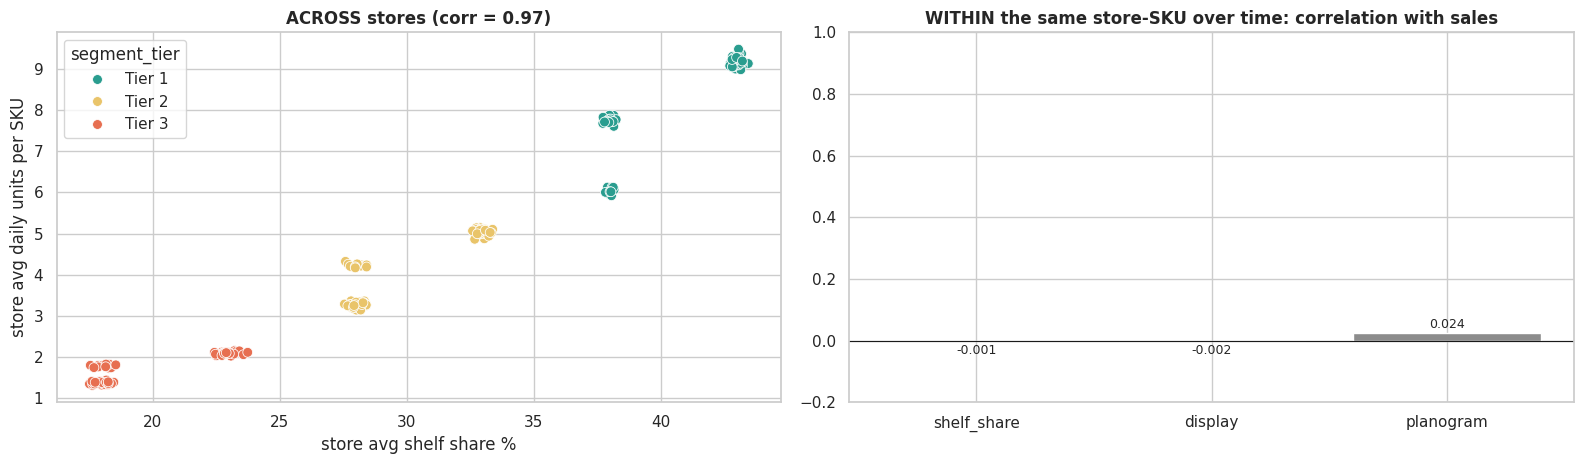

In [45]:
tmp = sof.loc[~sof.is_out_of_stock, ['store_id', 'sku_id', 'date', 'units_sold_daily']].assign(month=lambda d: d.date.dt.to_period('M'))
so_m = tmp.groupby(['store_id', 'sku_id', 'month']).units_sold_daily.mean().rename('units')
au_m = (audits.assign(month=audits.date.dt.to_period('M')).groupby(['store_id', 'sku_id', 'month'])
              .agg(shelf_share=('shelf_share_pct', 'mean'), display=('secondary_display', 'mean'), planogram=('planogram_compliance', 'mean')))
m = pd.concat([so_m, au_m], axis=1, join='inner').reset_index()
for c in ['units', 'shelf_share', 'display', 'planogram']:
    m[c + '_vs_usual'] = m[c] - m.groupby(['store_id', 'sku_id'])[c].transform('mean')
within = {c: np.corrcoef(m[c + '_vs_usual'], m['units_vs_usual'])[0, 1] for c in ['shelf_share', 'display', 'planogram']}

store_lvl = m.groupby('store_id')[['units', 'shelf_share']].mean().join(stores.set_index('store_id').segment_tier)
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
sns.scatterplot(data=store_lvl, x='shelf_share', y='units', hue='segment_tier', hue_order=TIER_ORDER, palette=TIER_COL, s=50, ax=axes[0])
axes[0].set_title(f"ACROSS stores (corr = {store_lvl[['shelf_share', 'units']].corr().iloc[0, 1]:.2f})")
axes[0].set_xlabel('store avg shelf share %'); axes[0].set_ylabel('store avg daily units per SKU')
axes[1].bar(list(within.keys()), list(within.values()), color='#8C8C8C'); label_bars(axes[1], '{:.3f}')
axes[1].set_ylim(-0.2, 1); axes[1].axhline(0, color='k', lw=0.8)
axes[1].set_title('WITHIN the same store-SKU over time: correlation with sales')
plt.tight_layout(); plt.show()
del tmp; _ = gc.collect()

**What we found:** Across stores the relationship is very strong, but the colours show it's just tight clusters of stores (one per tier and channel) stacked on top of each other. Within the same store-SKU over time, the correlations are basically **zero**. So in this data, better execution doesn't lead to more sales; big stores just do both.

That means we can't measure how much an "execution commitment" (like +10% shelf share) is worth, which is exactly what Module 3 Scenario A trades against a discount. Another assumption to agree on with the client.

### 8.6 Commercial guardrails
`dim_guardrails` sets the negotiation rules: a max extra discount, a minimum margin, and a required "give-back" from the store. We checked when the margin rule would actually kick in.

,channel,category,max_discount_pct,min_target_margin,required_exec_tradeoff
0,Modern Trade,Surface Cleaners,12.80,26.62,Secure +10% shelf share or place 1 secondary d...
1,Modern Trade,Dishwashing,11.34,22.26,Commit to featured endcap placement for 4 weeks
2,Modern Trade,Laundry,13.30,25.50,Secure +15% shelf share or place 1 secondary d...
3,Traditional Trade,Surface Cleaners,6.62,31.47,Secure +10% shelf share or place 1 secondary d...
4,Traditional Trade,Dishwashing,7.99,27.52,Achieve 100% MSL compliance + planogram adherence
5,Traditional Trade,Laundry,7.16,27.08,Commit to featured endcap placement for 4 weeks
6,Distributor,Surface Cleaners,17.80,23.45,Achieve 100% MSL compliance + planogram adherence
7,Distributor,Dishwashing,15.07,21.97,Secure +15% shelf share or place 1 secondary d...
8,Distributor,Laundry,16.34,17.41,Commit to featured endcap placement for 4 weeks


max_discount_allowed  discount_that_breaks_margin  min_margin_rule  worst_margin_at_max_discount
channel           category                                                                                                          
Distributor       Dishwashing                       15.1                         31.5             22.0                          37.0
                  Laundry                           16.3                         32.7             17.4                          33.6
                  Surface Cleaners                  17.8                         28.3             23.4                          33.3
Modern Trade      Dishwashing                       11.3                         31.2             22.3                          39.7
                  Laundry                           13.3                         25.4             25.5                          35.9
                  Surface Cleaners                  12.8                         25.2             26.6                          37.1
Traditional Trade Dishwashing                        8.0                         26.2             27.5                          41.9
                  Laundry                            7.2                         23.8             27.1                          40.1
                  Surface Cleaners                   6.6                         19.9             31.5                          41.3

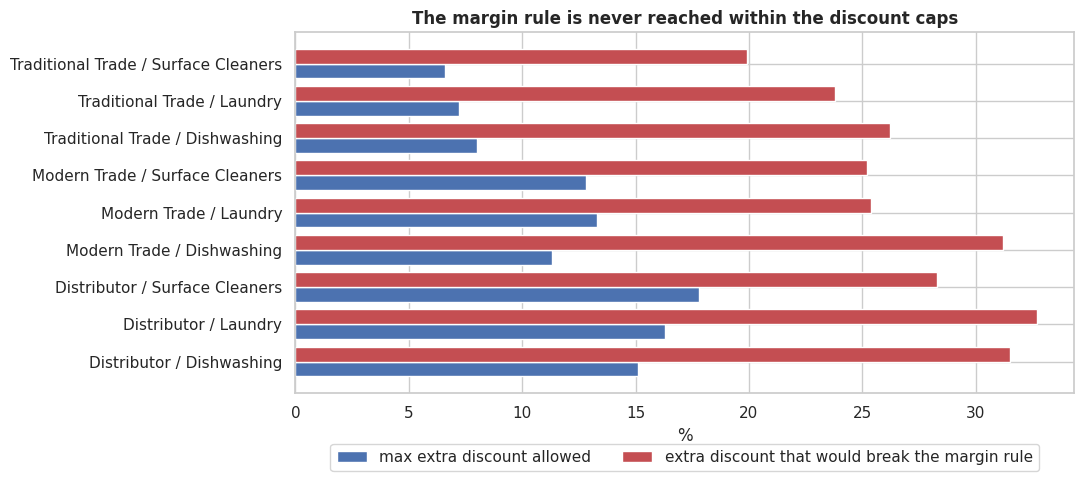

required_exec_tradeoff
Commit to featured endcap placement for 4 weeks         3
Secure +10% shelf share or place 1 secondary display    2
Secure +15% shelf share or place 1 secondary display    2
Achieve 100% MSL compliance + planogram adherence       2
Name: count, dtype: int64


In [46]:
display(guardrails)
gm = products.merge(guardrails, on='category')
gm['invoice_price'] = gm.list_price * (1 - 0.12)                     # worst invoice discount we saw (~12%)
gm['price_after_max'] = gm.invoice_price * (1 - gm.max_discount_pct / 100)
gm['margin_after_max_%'] = (gm.price_after_max - gm.unit_cost) / gm.price_after_max * 100
gm['extra_disc_to_break_margin_%'] = (1 - gm.unit_cost / ((1 - gm.min_target_margin / 100) * gm.invoice_price)) * 100
gsum = (gm.groupby(['channel', 'category'])
          .agg(max_discount_allowed=('max_discount_pct', 'first'), discount_that_breaks_margin=('extra_disc_to_break_margin_%', 'min'),
               min_margin_rule=('min_target_margin', 'first'), worst_margin_at_max_discount=('margin_after_max_%', 'min')).round(1))
display(gsum)

plot_df = gsum.reset_index()
labels = plot_df.channel + ' / ' + plot_df.category
y = np.arange(len(plot_df))
fig, ax = plt.subplots(figsize=(11, 5))
ax.barh(y - 0.2, plot_df.max_discount_allowed, height=0.4, color='#4C72B0', label='max extra discount allowed')
ax.barh(y + 0.2, plot_df.discount_that_breaks_margin, height=0.4, color='#C44E52', label='extra discount that would break the margin rule')
ax.set_yticks(y); ax.set_yticklabels(labels); ax.set_xlabel('%'); ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=2)
ax.set_title('The margin rule is never reached within the discount caps')
plt.tight_layout(); plt.show()
print(guardrails.required_exec_tradeoff.value_counts())

**What we found**
1. In every channel × category, the discount needed to break the **minimum margin** (~20–33%) is far above the **max discount allowed** (6.6–17.8%). Even starting from the worst invoice discount and adding the max on top, margin stays above 33%.
2. So in practice **only the discount cap decides** approve or reject. The margin rule never triggers, unless "margin" means something else (margin on price vs markup on cost, or margin after other costs).
3. The give-backs are free text in 4 flavours. To check them automatically we need to turn them into rules, e.g. "+15% shelf share" → compare with the latest audit. Open questions: is that +15 percentage points or +15% of the current share? Does "featured endcap" count as `secondary_display`?

## 9. Baseline OOS model (feasibility check)
Module 2 asks for a model that predicts whether a SKU will go out of stock at a store within 7 days, with **Precision ≥ 0.75, Recall ≥ 0.70 and AUC-ROC ≥ 0.80**. Since the EDA suggested OOS is hard to predict precisely (8.2), we built a quick baseline to see where we stand. This is *not* our final model.

### 9.1 Target and features
The brief says "`is_out_of_stock` at t+7 days", which can be read two ways, so we tested both:
1. `y_any7`: out of stock on **any** day in the next 7 days (we think this is what a rep actually cares about)
2. `y_day7`: out of stock on **exactly** day 7

**Features** (only using information available on day t):
1. stock level, sales speed over the last 7/14/28 days, **days of stock left** (stock ÷ recent daily sales)
2. days since the last delivery, share of recent days that were OOS, whether it's OOS today
3. latest audit before day t (planogram, shelf share, secondary display)
4. tier, channel, region, category, MSL flag, weekday, month

**How:** we reshape the data into a grid (one row per store-SKU, one column per calendar day), which makes rolling windows and "look 7 days ahead" easy. Missing days = zero sales and unchanged stock (from 3.7).

**Split:** 70/15/15 **by date**, not random. Neighbouring days are nearly identical, so a random split would leak the future. We also leave a 7-day gap between splits so labels don't peek into the next period, and we drop the January 2025 warm-up.

### 9.2 Building the features

In [47]:
del sof, msl_sd, msl_rows, au, pair, m, deliv, samp; _ = gc.collect()
key = ['store_id', 'sku_id']
so['oos_int'] = so.is_out_of_stock.astype(int)
wide = lambda col: so.pivot(index=key, columns='date', values=col).reindex(columns=all_days)
units_w, inv_w, oos_w = wide('units_sold_daily'), wide('inventory_level'), wide('oos_int')

observed = units_w.notna()          # True where the store-day was recorded
units_f = units_w.fillna(0)         # missing day = nothing sold
inv_f = inv_w.ffill(axis=1)         # missing day = stock unchanged
oos0 = oos_w.fillna(0)

def roll_sum(w, n):                 # rolling sum over the last n calendar days (including today)
    return w.T.rolling(n, min_periods=1).sum().T

vel7, vel14, vel28 = roll_sum(units_f, 7) / 7, roll_sum(units_f, 14) / 14, roll_sum(units_f, 28) / 28
days_cover = inv_f / (vel14 + 0.1)
prev_inv = inv_f.shift(1, axis=1)
delivery = (inv_f - (prev_inv - units_f)) > 0
col_idx = np.arange(inv_f.shape[1])
last_delivery = pd.DataFrame(np.where(delivery, col_idx, np.nan), index=inv_f.index, columns=inv_f.columns).ffill(axis=1)
days_since_delivery = col_idx - last_delivery
oos_rate_28 = roll_sum(oos0, 28) / roll_sum(observed.astype(float), 28)

cum = oos0.cumsum(axis=1)
future_oos_days = cum.shift(-7, axis=1) - cum                  # OOS days in (t, t+7]
y_any7 = (future_oos_days > 0).astype(float).where(future_oos_days.notna())
y_day7 = oos_w.shift(-7, axis=1)                               # OOS exactly on day t+7 (NaN if that day is missing)

n_pairs, n_days = units_w.shape
grid = {'inventory_level': inv_f, 'vel7': vel7, 'vel14': vel14, 'vel28': vel28, 'days_cover': days_cover,
        'days_since_delivery': days_since_delivery, 'oos_rate_28': oos_rate_28, 'is_oos_now': oos0, 'y_any7': y_any7, 'y_day7': y_day7}
df = pd.DataFrame({'store_id': np.repeat(units_w.index.get_level_values('store_id').to_numpy(), n_days),
                   'sku_id': np.repeat(units_w.index.get_level_values('sku_id').to_numpy(), n_days),
                   'date': np.tile(units_w.columns.to_numpy(), n_pairs)})
for name, mat in grid.items():
    df[name] = mat.to_numpy(dtype=float).ravel()
df = df[observed.to_numpy().ravel()].reset_index(drop=True)
del grid, vel7, vel14, vel28, days_cover, days_since_delivery, last_delivery, oos_rate_28, cum, future_oos_days, prev_inv, delivery
_ = gc.collect()

aud = audits.sort_values('date')[['date', 'store_id', 'sku_id', 'planogram_compliance', 'shelf_share_pct', 'secondary_display']]
df = pd.merge_asof(df.sort_values('date'), aud, on='date', by=key, direction='backward')   # latest audit on or before day t
df = (df.merge(stores[['store_id', 'channel', 'segment_tier', 'region']], on='store_id')
        .merge(products[['sku_id', 'category', 'is_msl']], on='sku_id'))
for c in ['channel', 'segment_tier', 'region', 'category']:
    df[c] = df[c].astype('category')
for c in ['planogram_compliance', 'secondary_display', 'is_msl']:
    df[c] = df[c].astype(float)
df['dow'], df['month'] = df.date.dt.dayofweek, df.date.dt.month
print(df.shape, '| OOS in next 7 days:', round(df.y_any7.mean(), 3), '| OOS exactly on day 7:', round(df.y_day7.mean(), 3))

(1656756, 23) | OOS in next 7 days: 0.13 | OOS exactly on day 7: 0.061


### 9.3 Training and evaluation
For each model we pick the probability threshold on the **validation** set (the highest precision that still catches ≥ 70% of stock-outs, the brief's recall target), then report everything on the **test** set. We also compare against a dead-simple rule: *flag it if there are fewer than 7 days of stock left*.

In [48]:
model_df = df[df.date >= '2025-02-01']
days = pd.DatetimeIndex(model_df.date.unique()).sort_values()
cut1, cut2 = days[int(0.70 * len(days))], days[int(0.85 * len(days))]
gap = pd.Timedelta(days=7)
split = lambda d: (d[d.date < cut1 - gap], d[(d.date >= cut1) & (d.date < cut2 - gap)], d[d.date >= cut2])
print(f'train: until {(cut1 - gap).date()} | validation: {cut1.date()} to {(cut2 - gap).date()} | test: {cut2.date()} onwards')

FULL = ['inventory_level', 'vel7', 'vel14', 'vel28', 'days_cover', 'days_since_delivery', 'oos_rate_28', 'is_oos_now',
        'planogram_compliance', 'shelf_share_pct', 'secondary_display', 'channel', 'segment_tier', 'region', 'category', 'is_msl', 'dow', 'month']
BRIEF = ['vel7', 'inventory_level', 'planogram_compliance', 'shelf_share_pct', 'channel', 'is_msl']   # the brief's suggested inputs

def pick_threshold(y, p, min_recall=0.70):
    prec, rec, thr = precision_recall_curve(y, p)
    ok = np.where(rec[:-1] >= min_recall)[0]
    return thr[ok[np.argmax(prec[ok])]]

def run(target, feats, name):
    tr, va, te = split(model_df.dropna(subset=[target]))
    clf = lgb.LGBMClassifier(n_estimators=500, learning_rate=0.05, num_leaves=63, random_state=42, verbose=-1)
    clf.fit(tr[feats], tr[target].astype(int), eval_set=[(va[feats], va[target].astype(int))],
            callbacks=[lgb.early_stopping(30, verbose=False)])
    p_va, p_te = clf.predict_proba(va[feats])[:, 1], clf.predict_proba(te[feats])[:, 1]
    y_te = te[target].astype(int).to_numpy()
    t = pick_threshold(va[target].astype(int), p_va)
    pred = (p_te >= t).astype(int)
    return ({'model': name, 'target': target, 'test_rows': len(te), 'base_rate': y_te.mean(), 'AUC': roc_auc_score(y_te, p_te),
             'precision': precision_score(y_te, pred), 'recall': recall_score(y_te, pred), 'threshold': t},
            (clf, y_te, p_te, feats))

results, fitted = [], {}
for target, feats, name in [('y_any7', FULL, 'LightGBM - all features'), ('y_any7', BRIEF, "LightGBM - brief's 6 features"),
                            ('y_day7', FULL, 'LightGBM - OOS exactly on day 7')]:
    res, fit = run(target, feats, name)
    results.append(res); fitted[name] = fit

_, _, te_rule = split(model_df.dropna(subset=['y_any7']))
rule_pred = (te_rule.days_cover < 7).astype(int)
results.append({'model': 'Rule - fewer than 7 days of stock left', 'target': 'y_any7', 'test_rows': len(te_rule),
                'base_rate': te_rule.y_any7.mean(), 'AUC': roc_auc_score(te_rule.y_any7, -te_rule.days_cover),
                'precision': precision_score(te_rule.y_any7, rule_pred), 'recall': recall_score(te_rule.y_any7, rule_pred), 'threshold': np.nan})
res_df = pd.DataFrame(results).set_index('model')
res_df['meets_brief'] = (res_df.AUC >= 0.80) & (res_df.precision >= 0.75) & (res_df.recall >= 0.70)
res_df.round(3)

train: until 2026-01-20 | validation: 2026-01-27 to 2026-04-07 | test: 2026-04-14 onwards


,target,test_rows,base_rate,AUC,precision,recall,threshold,meets_brief
model,,,,,,,,
LightGBM - all features,y_any7,215316,0.13,0.925,0.546,0.689,0.293,False
LightGBM - brief's 6 features,y_any7,215316,0.13,0.920,0.523,0.712,0.272,False
LightGBM - OOS exactly on day 7,y_day7,149614,0.06,0.830,0.166,0.692,0.142,False
Rule - fewer than 7 days of stock left,y_any7,215316,0.13,0.916,0.397,0.878,NaN,False


### 9.4 ROC and precision-recall curves

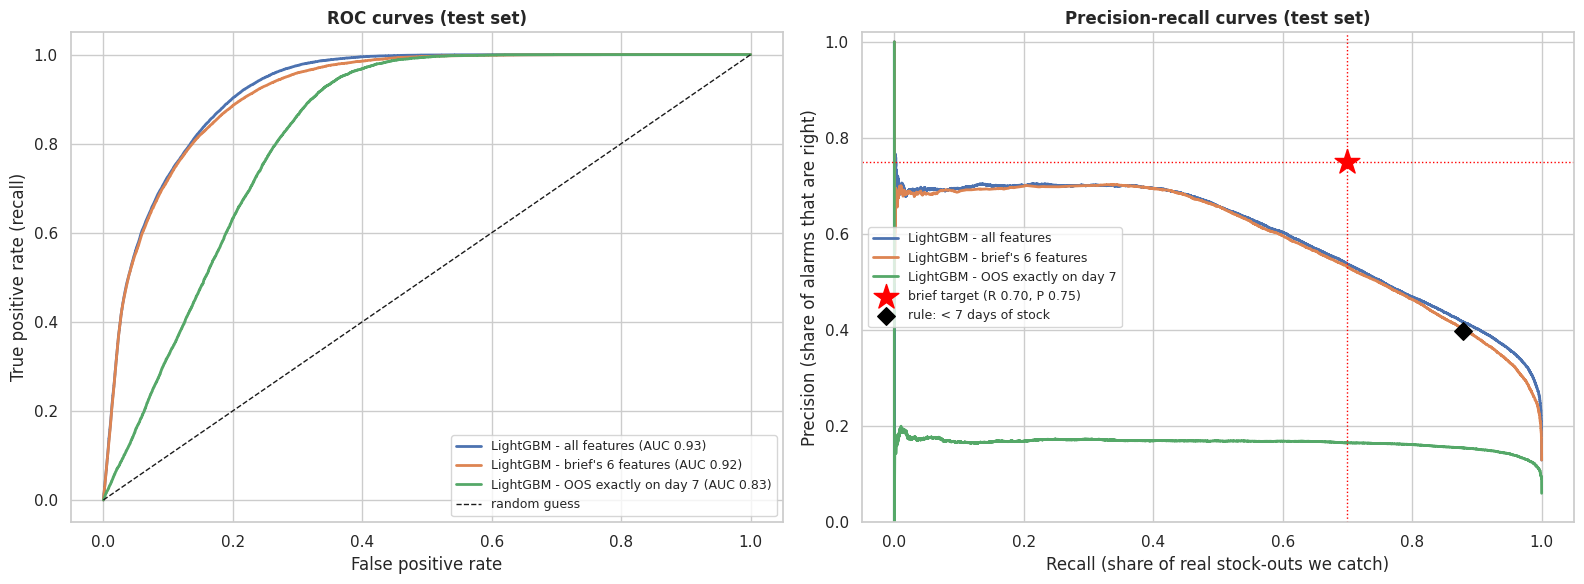

In [49]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for name, (clf, y, p, feats) in fitted.items():
    fpr, tpr, _ = roc_curve(y, p)
    axes[0].plot(fpr, tpr, lw=2, label=f'{name} (AUC {roc_auc_score(y, p):.2f})')
    prec, rec, _ = precision_recall_curve(y, p)
    axes[1].plot(rec, prec, lw=2, label=name)
axes[0].plot([0, 1], [0, 1], 'k--', lw=1, label='random guess')
axes[0].set_xlabel('False positive rate'); axes[0].set_ylabel('True positive rate (recall)')
axes[0].set_title('ROC curves (test set)'); axes[0].legend(loc='lower right', fontsize=9)
r = res_df.loc['Rule - fewer than 7 days of stock left']
axes[1].axvline(0.70, color='red', ls=':', lw=1); axes[1].axhline(0.75, color='red', ls=':', lw=1)
axes[1].scatter([0.70], [0.75], marker='*', s=350, color='red', zorder=5, label='brief target (R 0.70, P 0.75)')
axes[1].scatter([r.recall], [r.precision], marker='D', s=80, color='black', zorder=5, label='rule: < 7 days of stock')
axes[1].set_xlabel('Recall (share of real stock-outs we catch)'); axes[1].set_ylabel('Precision (share of alarms that are right)')
axes[1].set_title('Precision-recall curves (test set)'); axes[1].legend(loc='center left', fontsize=9); axes[1].set_ylim(0, 1.02)
plt.tight_layout(); plt.show()

### 9.5 Threshold, confusion matrix and feature importance

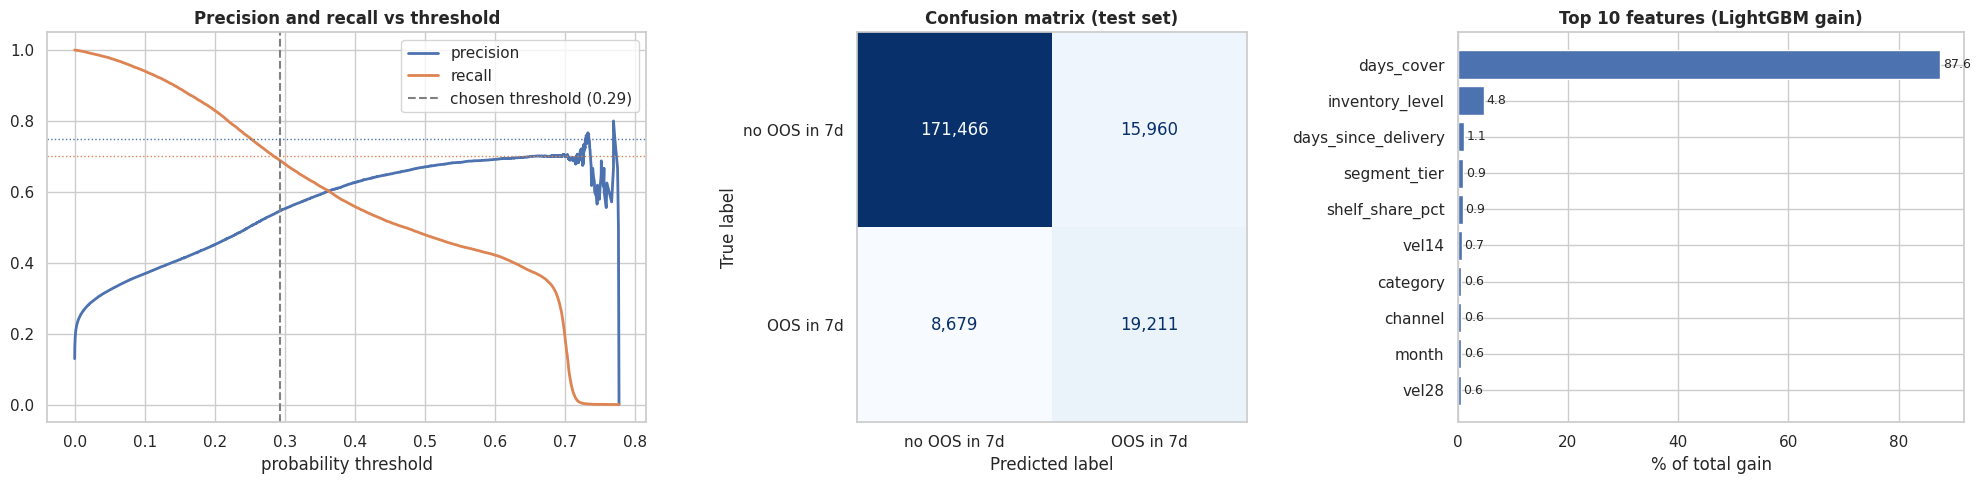

In [50]:
clf, y, p, feats = fitted['LightGBM - all features']
t = res_df.loc['LightGBM - all features', 'threshold']
prec, rec, thr = precision_recall_curve(y, p)
fig, axes = plt.subplots(1, 3, figsize=(20, 5), gridspec_kw={'width_ratios': [1.3, 1, 1.1]})
axes[0].plot(thr, prec[:-1], label='precision', lw=2); axes[0].plot(thr, rec[:-1], label='recall', lw=2)
axes[0].axvline(t, color='grey', ls='--', label=f'chosen threshold ({t:.2f})')
axes[0].axhline(0.75, color='C0', ls=':', lw=1); axes[0].axhline(0.70, color='C1', ls=':', lw=1)
axes[0].set_xlabel('probability threshold'); axes[0].set_title('Precision and recall vs threshold'); axes[0].legend()
ConfusionMatrixDisplay(confusion_matrix(y, (p >= t).astype(int)), display_labels=['no OOS in 7d', 'OOS in 7d']).plot(
    ax=axes[1], cmap='Blues', values_format=',', colorbar=False)
axes[1].set_title('Confusion matrix (test set)'); axes[1].grid(False)
imp = pd.Series(clf.booster_.feature_importance('gain'), index=feats)
imp = (imp / imp.sum() * 100).sort_values().tail(10)
axes[2].barh(imp.index, imp.values, color='#4C72B0'); label_bars(axes[2], '{:.1f}')
axes[2].set_xlabel('% of total gain'); axes[2].set_title('Top 10 features (LightGBM gain)')
plt.tight_layout(); plt.show()

### 9.6 What the baseline tells us
1. **AUC is easy:** ~0.92, well above the 0.80 target.
2. **Precision is the problem:** when we catch ~70% of stock-outs, only about half of the alarms are right (precision ~0.52–0.55 vs the 0.75 target). On the PR curve, precision **never gets above ~0.70 at any recall**, so the red star is out of reach with this setup.
3. The **brief's 6 features** do almost as well as all of ours.
4. **"Exactly day 7"** is much harder (precision ~0.17), because being OOS on one specific day is a lot noisier than "sometime this week".
5. The **"< 7 days of stock" rule** sits almost exactly on the model's PR curve, and the model relies mostly on days of stock left. So right now the model is basically a fine-tuned version of that rule.

**Why:** from 8.2, deliveries arrive at irregular times, often after the shelf is already empty. When stock is low, the model can't know if the truck comes tomorrow or next week, so there's a ceiling on precision.

**Ideas to improve:** features for each store-SKU's usual delivery rhythm and reorder level; choosing the threshold by business cost (missed stock-out vs wasted visit) instead of a fixed recall; and checking with Dr. Masse which target he means and whether the precision target is firm.

## 10. Key insights and what they mean for our build

| # | Insight | Where | What it means for us |
|---|---|---|---|
| 1 | Data is clean, but ~30% of store-days are missing and nothing happens on them | 3.2–3.7 | Treat missing days as zero sales + unchanged stock |
| 2 | Data ends 30 Jun 2026; brief examples use later dates | 3.5 | Treat 30 Jun 2026 as "today" in the app and chatbot |
| 3 | Store tier drives sales, execution and OOS | 5.1, 5.5, 8.1 | Tier should be a main filter and a key model feature |
| 4 | Region barely matters | 5.4, 7.4 | A map is nice to have, not the main story |
| 5 | Strong, category-specific seasonality; weekends +23% | 6.2–6.4 | Use seasonal and weekday factors in the perfect order |
| 6 | MSL compliance ~40% (strict); KPI values depend heavily on definitions | 7.2, 7.5 | Agree KPI definitions with Globant before building the dashboard |
| 7 | Monthly sell-in gap is distorted by the number of Mondays | 7.3 | Compare sell-in vs sell-out by week |
| 8 | Sell-in gap is a fixed number per channel; invoices don't match deliveries | 8.3 | Ask what story the gap KPI should tell |
| 9 | No price signal: no prices in sell-out, random discounts | 8.4 | Elasticity has to be an assumption (slider) |
| 10 | Execution doesn't move sales within a store | 8.5 | The value of execution commitments has to be an assumption |
| 11 | The margin guardrail never triggers | 8.6 | Only the discount cap decides; confirm the margin definition |
| 12 | Irregular deliveries cap OOS precision (~0.55 at 0.70 recall) | 8.2, 9 | Discuss the target definition and metrics with Dr. Masse |

## 11. Questions for Dr. Masse
1. What do the missing ~30% of store-days represent (store closed, not reported, or noise)?
2. OOS target: any day in the next 7 days, or exactly day 7? Are the precision and recall targets fixed?
3. How should MSL compliance and planogram compliance be defined? (We get ~13% to ~94% depending on the definition, vs 62% in the brief.)
4. Is the Traditional Trade sell-in gap intentional? What should the gap KPI show?
5. Can we use an assumed elasticity and an assumed execution uplift for Module 3?
6. Margin: margin on price or markup on cost? Is "+15% shelf share" in percentage points or relative? Does "featured endcap" = `secondary_display`?
7. How should we treat the Distributor "stores"?
8. Should the app treat 30 June 2026 as "today"?
9. There's no rep-to-store table. Can we create our own territories for the Field Rep view?

## 12. Next steps
1. Send these questions to Dr. Masse and agree on the KPI definitions.
2. Load the data into a small database (DuckDB) with one clean view per KPI, so the dashboard, model and chatbot all use the same numbers.
3. Build dashboard v1 using the scorecard and trend charts from section 7.
4. Improve the OOS model (delivery rhythm features, cost-based threshold) and build the store visit ranking on top of it.
5. Use the seasonality findings from section 6 for the perfect order suggestion.